file name

In [1]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


file finding

In [2]:
from pathlib import Path

BASE_DIR = Path(
    "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET"
)

print("Folder exists:", BASE_DIR.exists())

if BASE_DIR.exists():
    print("\nFiles inside dataset folder:")

    for item in BASE_DIR.iterdir():
        print(item.name)
else:
    print("Dataset folder not found!")

Folder exists: True

Files inside dataset folder:
archive.zip
motum.zip
brisc_preprocessing_sample
BRISC_preprocessed_256
BRISC_classification_256
MOTUM_preprocessed_2D
MOTUM_preprocessed_256
brisc_mask_visual_inspection.png
BRISC_RAW
BRISC_mask_visual_inspection_step10.png
BRISC_preprocessed_256_v2


Step 2: Original ZIP files inspection

In [3]:
import zipfile
from pathlib import Path

BASE_DIR = Path(
    "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET"
)

ZIP_FILES = [
    "archive.zip",
    "motum.zip"
]

for zip_name in ZIP_FILES:

    zip_path = BASE_DIR / zip_name

    print("\nDataset:", zip_name)
    print("Exists:", zip_path.exists())

    if zip_path.exists():

        with zipfile.ZipFile(zip_path, "r") as zip_ref:

            files = zip_ref.namelist()

            print("Total files:", len(files))

            print("\nFirst 15 files:")

            for file in files[:15]:
                print(file)


Dataset: archive.zip
Exists: True
Total files: 15591

First 15 files:
brisc2025/README.md
brisc2025/classification_task/test/glioma/brisc2025_test_00001_gl_ax_t1.jpg
brisc2025/classification_task/test/glioma/brisc2025_test_00002_gl_ax_t1.jpg
brisc2025/classification_task/test/glioma/brisc2025_test_00003_gl_ax_t1.jpg
brisc2025/classification_task/test/glioma/brisc2025_test_00004_gl_ax_t1.jpg
brisc2025/classification_task/test/glioma/brisc2025_test_00005_gl_ax_t1.jpg
brisc2025/classification_task/test/glioma/brisc2025_test_00006_gl_ax_t1.jpg
brisc2025/classification_task/test/glioma/brisc2025_test_00007_gl_ax_t1.jpg
brisc2025/classification_task/test/glioma/brisc2025_test_00008_gl_ax_t1.jpg
brisc2025/classification_task/test/glioma/brisc2025_test_00009_gl_ax_t1.jpg
brisc2025/classification_task/test/glioma/brisc2025_test_00010_gl_ax_t1.jpg
brisc2025/classification_task/test/glioma/brisc2025_test_00011_gl_ax_t1.jpg
brisc2025/classification_task/test/glioma/brisc2025_test_00012_gl_ax_t1.j

Cell 3: Dataset Structure Analysis

In [4]:
import zipfile
from collections import Counter
from pathlib import Path

BASE_DIR = Path(
    "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET"
)

datasets = {
    "BRISC": BASE_DIR / "archive.zip",
    "MOTUM": BASE_DIR / "motum.zip"
}

for dataset_name, zip_path in datasets.items():

    print("\n" + "=" * 50)
    print("DATASET:", dataset_name)
    print("=" * 50)

    with zipfile.ZipFile(zip_path, "r") as zip_ref:

        files = [
            f for f in zip_ref.namelist()
            if not f.endswith("/")
        ]

        extensions = Counter(
            Path(f).suffix.lower()
            for f in files
        )

        print("\nTotal files:", len(files))

        print("\nFile extensions:")

        for ext, count in extensions.items():
            print(ext, ":", count)

        print("\nMain folders:")

        folders = Counter(
            f.split("/")[1]
            for f in files
            if len(f.split("/")) > 1
        )

        for folder, count in folders.items():
            print(folder, ":", count)

        print("\nSample relevant files:")

        for f in files:
            if any(x in f.lower() for x in [
                "seg", "mask", "t1ce", "flair"
            ]):
                print(f)
                if files.index(f) > 30:
                    break


DATASET: BRISC

Total files: 15591

File extensions:
.md : 1
.jpg : 10793
.csv : 1
.sha256 : 2
.json : 1
.png : 4793

Main folders:
README.md : 1
classification_task : 6000
manifest.csv : 1
manifest.csv.sha256 : 1
manifest.json : 1
manifest.json.sha256 : 1
segmentation_task : 9586

Sample relevant files:
brisc2025/segmentation_task/test/images/brisc2025_test_00001_gl_ax_t1.jpg

DATASET: MOTUM

Total files: 932

File extensions:
.yml : 1
.json : 268
.csv : 268
.gz : 390
.zip : 1
 : 1
.xlsx : 1
.md : 1
.nii : 1

Main folders:
datacite.yml : 1
derivatives : 670
DICOM.zip : 1
LICENSE : 1
Participants.xlsx : 1
README.md : 1
sub-0001 : 4
sub-0002 : 4
sub-0003 : 4
sub-0004 : 4
sub-0005 : 4
sub-0006 : 4
sub-0007 : 4
sub-0008 : 4
sub-0009 : 4
sub-0010 : 4
sub-0011 : 4
sub-0012 : 4
sub-0013 : 4
sub-0014 : 4
sub-0015 : 4
sub-0016 : 4
sub-0017 : 4
sub-0018 : 4
sub-0019 : 4
sub-0020 : 4
sub-0021 : 4
sub-0022 : 4
sub-0023 : 4
sub-0024 : 4
sub-0025 : 4
sub-0026 : 4
sub-0027 : 4
sub-0028 : 4
sub-0029

Step 4: MOTUM-এর MRI modality যাচাই

In [5]:
import zipfile

motum_zip = BASE_DIR / "motum.zip"

with zipfile.ZipFile(motum_zip, "r") as zip_ref:

    files = [
        f for f in zip_ref.namelist()
        if f.endswith((".nii", ".nii.gz"))
    ]

    subjects = {}

    for f in files:

        parts = f.split("/")

        subject = next(
            (p for p in parts if p.startswith("sub-")),
            "Unknown"
        )

        subjects.setdefault(subject, []).append(f)

    print("Total subjects:", len(subjects))

    for subject, subject_files in sorted(subjects.items()):

        print("\n", subject)

        for f in subject_files:
            print("  ", f)

Total subjects: 67

 sub-0001
   motum/derivatives/sub-0001/flair_seg_label1.nii.gz
   motum/derivatives/sub-0001/t1ce_seg_label2.nii.gz
   motum/sub-0001/anat/sub-0001_flair.nii.gz
   motum/sub-0001/anat/sub-0001_t1.nii.gz
   motum/sub-0001/anat/sub-0001_t1ce.nii.gz
   motum/sub-0001/anat/sub-0001_t2.nii.gz

 sub-0002
   motum/derivatives/sub-0002/flair_seg_label1.nii.gz
   motum/derivatives/sub-0002/t1ce_seg_label2.nii.gz
   motum/sub-0002/anat/sub-0002_flair.nii.gz
   motum/sub-0002/anat/sub-0002_t1.nii.gz
   motum/sub-0002/anat/sub-0002_t1ce.nii.gz
   motum/sub-0002/anat/sub-0002_t2.nii.gz

 sub-0003
   motum/derivatives/sub-0003/flair_seg_label1.nii.gz
   motum/derivatives/sub-0003/t1ce_seg_label2.nii.gz
   motum/sub-0003/anat/sub-0003_flair.nii.gz
   motum/sub-0003/anat/sub-0003_t1.nii.gz
   motum/sub-0003/anat/sub-0003_t1ce.nii.gz
   motum/sub-0003/anat/sub-0003_t2.nii.gz

 sub-0004
   motum/derivatives/sub-0004/flair_seg_label1.nii.gz
   motum/derivatives/sub-0004/t1ce_seg_labe

Cell 4: Extract BRISC Dataset

In [7]:
import zipfile
from pathlib import Path

BASE_DIR = Path(
    "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET"
)

BRISC_ZIP = BASE_DIR / "archive.zip"
BRISC_RAW = BASE_DIR / "BRISC_RAW"

if not BRISC_RAW.exists():

    BRISC_RAW.mkdir(parents=True)

    with zipfile.ZipFile(BRISC_ZIP, "r") as zip_ref:

        zip_ref.extractall(BRISC_RAW)

    print("BRISC extraction completed!")

else:
    print("BRISC_RAW already exists. Skipping extraction.")

print("\nBRISC folder:", BRISC_RAW)

print("\nExtracted folders:")

for item in (BRISC_RAW / "brisc2025").iterdir():
    print(item.name)

BRISC_RAW already exists. Skipping extraction.

BRISC folder: /content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/BRISC_RAW

Extracted folders:
README.md
classification_task
manifest.csv
manifest.csv.sha256
manifest.json
manifest.json.sha256
segmentation_task


Step 1: Cell 5 রান করো

In [8]:
from pathlib import Path

BRISC_ROOT = BRISC_RAW / "brisc2025"

classification_dir = BRISC_ROOT / "classification_task"
segmentation_dir = BRISC_ROOT / "segmentation_task"

print("CLASSIFICATION DATASET")

for split in ["train", "test"]:

    split_dir = classification_dir / split

    total = sum(
        len(list((split_dir / cls).glob("*.jpg")))
        for cls in ["glioma", "meningioma",
                    "no_tumor", "pituitary"]
    )

    print(split, ":", total)


print("\nSEGMENTATION DATASET")

for split in ["train", "test"]:

    images = list(
        (segmentation_dir / split / "images").glob("*.jpg")
    )

    masks = list(
        (segmentation_dir / split / "masks").glob("*.png")
    )

    print("\n", split)
    print("Images:", len(images))
    print("Masks:", len(masks))

CLASSIFICATION DATASET
train : 5000
test : 1000

SEGMENTATION DATASET

 train
Images: 3933
Masks: 3933

 test
Images: 860
Masks: 860


Step 3: Image ও Mask-এর original properties পরীক্ষা


========== TRAIN ==========
Matched pairs: 3933
Images without masks: 0
Masks without images: 0

Sample: brisc2025_train_00001_gl_ax_t1
Image shape: (512, 512, 3)
Image dtype: uint8
Image range: 0 - 255

Mask shape: (512, 512)
Mask dtype: uint8

Mask unique values and pixel counts:
[(0, 244991), (1, 398), (2, 227), (3, 117), (4, 39), (5, 20), (6, 6), (7, 1), (248, 2), (249, 2), (250, 26), (251, 44), (252, 111), (253, 220), (254, 413), (255, 15527)]


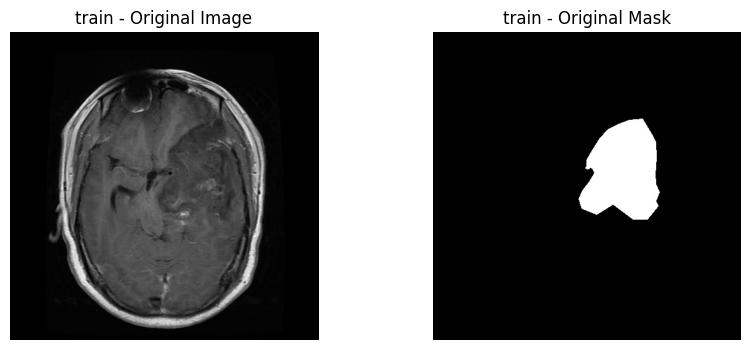


========== TEST ==========
Matched pairs: 860
Images without masks: 0
Masks without images: 0

Sample: brisc2025_test_00001_gl_ax_t1
Image shape: (512, 512, 3)
Image dtype: uint8
Image range: 0 - 255

Mask shape: (512, 512)
Mask dtype: uint8

Mask unique values and pixel counts:
[(0, 260646), (1, 170), (2, 110), (3, 37), (4, 19), (5, 10), (7, 1), (248, 1), (249, 1), (250, 8), (251, 19), (252, 26), (253, 63), (254, 134), (255, 899)]


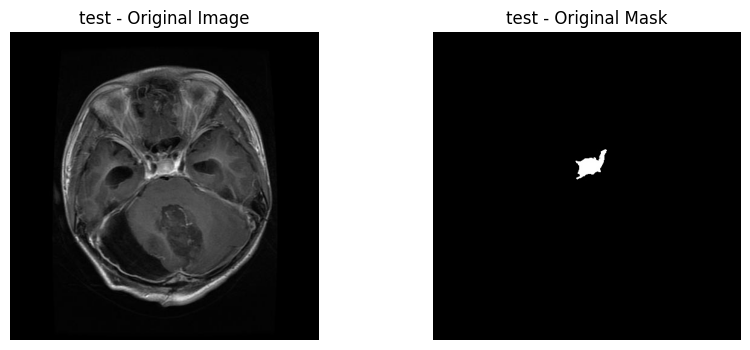

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

for split in ["train", "test"]:

    image_dir = segmentation_dir / split / "images"
    mask_dir = segmentation_dir / split / "masks"

    image_files = sorted(image_dir.glob("*.jpg"))
    mask_files = sorted(mask_dir.glob("*.png"))

    image_names = {f.stem for f in image_files}
    mask_names = {f.stem for f in mask_files}

    matched_names = image_names & mask_names

    print("\n==========", split.upper(), "==========")
    print("Matched pairs:", len(matched_names))
    print("Images without masks:", len(image_names - mask_names))
    print("Masks without images:", len(mask_names - image_names))

    if matched_names:

        sample_name = sorted(matched_names)[0]

        image_path = image_dir / (sample_name + ".jpg")
        mask_path = mask_dir / (sample_name + ".png")

        image = np.array(Image.open(image_path))
        mask = np.array(Image.open(mask_path))

        print("\nSample:", sample_name)
        print("Image shape:", image.shape)
        print("Image dtype:", image.dtype)
        print("Image range:", image.min(), "-", image.max())

        print("\nMask shape:", mask.shape)
        print("Mask dtype:", mask.dtype)

        values, counts = np.unique(
            mask, return_counts=True
        )

        print("\nMask unique values and pixel counts:")
        print(list(zip(values.tolist(), counts.tolist())))

        plt.figure(figsize=(10, 4))

        plt.subplot(1, 2, 1)
        plt.imshow(image)
        plt.title(f"{split} - Original Image")
        plt.axis("off")

        plt.subplot(1, 2, 2)
        plt.imshow(mask, cmap="gray")
        plt.title(f"{split} - Original Mask")
        plt.axis("off")

        plt.show()

Step 4: README ও mask encoding পরীক্ষা

In [10]:
from PIL import Image
import numpy as np

# Read BRISC README
readme_path = BRISC_ROOT / "README.md"

print("========== README ==========")

with open(readme_path, "r", encoding="utf-8") as f:
    print(f.read())

# Inspect one original mask
mask_path = (
    segmentation_dir / "train" / "masks" /
    "brisc2025_train_00001_gl_ax_t1.png"
)

mask_pil = Image.open(mask_path)

print("\n========== MASK DETAILS ==========")
print("Image mode:", mask_pil.mode)
print("Image format:", mask_pil.format)
print("PNG info:", mask_pil.info)

mask = np.array(mask_pil)

print("Shape:", mask.shape)
print("Minimum:", mask.min())
print("Maximum:", mask.max())
print("Unique values:", np.unique(mask))

========== README ==========
# BRISC 2025 — Brain Tumor MRI Dataset

> **BRISC** (BRain tumor Image Segmentation & Classification) — a curated, expert-annotated T1 MRI dataset for multi-class brain tumor classification and pixel-wise segmentation.

[ArXiv preprint (Fateh et al., 2025)](https://arxiv.org/abs/2506.14318)

---

## 🚀 Overview

BRISC is designed to address common shortcomings in existing public brain MRI collections (e.g., class imbalance, limited tumor types, and annotation inconsistency). It provides high-quality, physician-validated pixel-level masks and a balanced multi-class classification split, suitable for benchmarking segmentation and classification algorithms as well as multi-task learning research.

**Highlights**
- 6,000 T1-weighted MRI slices (5,000 train / 1,000 test)
- Four classes: **Glioma**, **Meningioma**, **Pituitary Tumor**, **No Tumor**
- Pixel-wise segmentation masks reviewed by radiologists
- Slices from three anatomical planes: **Axial**, **Coronal*

Step 5: তিনটি threshold তুলনা করব

Original mask: [  0   1   2   3   4   5   6   7 248 249 250 251 252 253 254 255]

Foreground pixel comparison:
Threshold > 0: 17153
Threshold >= 128: 16345
Threshold == 255: 15527


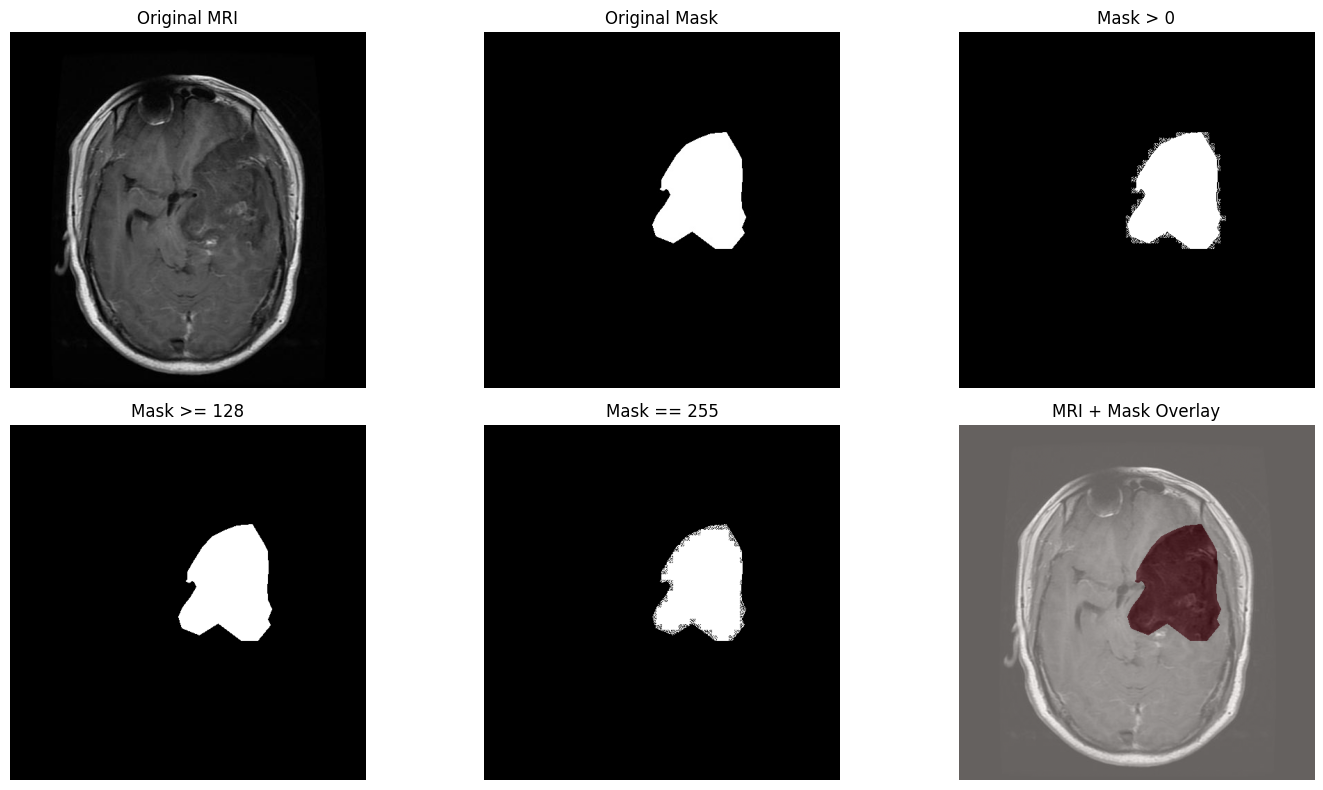

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

image_path = (
    segmentation_dir / "train" / "images" /
    "brisc2025_train_00001_gl_ax_t1.jpg"
)

mask_path = (
    segmentation_dir / "train" / "masks" /
    "brisc2025_train_00001_gl_ax_t1.png"
)

image = np.array(Image.open(image_path).convert("RGB"))
mask = np.array(Image.open(mask_path))

# Three threshold comparisons
mask_gt0 = (mask > 0).astype(np.uint8)
mask_ge128 = (mask >= 128).astype(np.uint8)
mask_eq255 = (mask == 255).astype(np.uint8)

print("Original mask:", np.unique(mask))
print("\nForeground pixel comparison:")

print("Threshold > 0:", np.sum(mask_gt0))
print("Threshold >= 128:", np.sum(mask_ge128))
print("Threshold == 255:", np.sum(mask_eq255))

# Visualization
plt.figure(figsize=(15, 8))

plt.subplot(2, 3, 1)
plt.imshow(image)
plt.title("Original MRI")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(mask, cmap="gray")
plt.title("Original Mask")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(mask_gt0, cmap="gray")
plt.title("Mask > 0")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(mask_ge128, cmap="gray")
plt.title("Mask >= 128")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(mask_eq255, cmap="gray")
plt.title("Mask == 255")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(image)
plt.imshow(mask_ge128, cmap="Reds", alpha=0.4)
plt.title("MRI + Mask Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

২. Image না পাঠিয়ে Colab-এ পরীক্ষা করো

In [12]:
print("MRI image shape:", image.shape)
print("Mask shape:", mask.shape)

print("\nMask statistics:")
print("Minimum:", mask.min())
print("Maximum:", mask.max())

print("\nBackground pixels:", np.sum(mask == 0))
print("Low intensity (1-127):", np.sum((mask >= 1) & (mask < 128)))
print("High intensity (128-254):", np.sum((mask >= 128) & (mask < 255)))
print("White pixels (255):", np.sum(mask == 255))

MRI image shape: (512, 512, 3)
Mask shape: (512, 512)

Mask statistics:
Minimum: 0
Maximum: 255

Background pixels: 244991
Low intensity (1-127): 808
High intensity (128-254): 818
White pixels (255): 15527


Step 1: Train ও Test Mask পরীক্ষা

In [13]:
from collections import Counter
from PIL import Image
import numpy as np

for split in ["train", "test"]:

    mask_dir = segmentation_dir / split / "masks"
    mask_files = list(mask_dir.glob("*.png"))

    total_counts = Counter()

    for mask_file in mask_files:
        mask = np.array(Image.open(mask_file).convert("L"))
        total_counts.update(mask.ravel().tolist())

    print(f"\n{split.upper()} MASK")
    print("Total masks:", len(mask_files))

    print("Background (0):", total_counts[0])

    print("Low values (1-127):",
          sum(total_counts[i] for i in range(1, 128)))

    print("High values (128-254):",
          sum(total_counts[i] for i in range(128, 255)))

    print("White (255):", total_counts[255])


TRAIN MASK
Total masks: 3933
Background (0): 996150074
Low values (1-127): 1810108
High values (128-254): 1644508
White (255): 14577331

TEST MASK
Total masks: 860
Background (0): 204661048
Low values (1-127): 375608
High values (128-254): 341339
White (255): 3240931


Step 06 — Mask Image Dimension Verification

In [14]:
# Step 06: Mask Image Dimension Verification

from collections import Counter
from PIL import Image

for split in ["train", "test"]:

    mask_dir = segmentation_dir / split / "masks"
    mask_files = list(mask_dir.glob("*.png"))

    size_counts = Counter()

    for mask_file in mask_files:
        with Image.open(mask_file) as img:
            size_counts[img.size] += 1

    print(f"\n{split.upper()} MASK SIZES")
    print("Total masks:", len(mask_files))

    for size, count in size_counts.items():
        print("Size:", size, "| Count:", count)


TRAIN MASK SIZES
Total masks: 3933
Size: (512, 512) | Count: 3766
Size: (256, 256) | Count: 25
Size: (442, 442) | Count: 4
Size: (502, 502) | Count: 1
Size: (474, 474) | Count: 2
Size: (940, 900) | Count: 1
Size: (900, 741) | Count: 1
Size: (226, 212) | Count: 1
Size: (420, 264) | Count: 1
Size: (630, 423) | Count: 1
Size: (209, 225) | Count: 1
Size: (252, 303) | Count: 1
Size: (239, 224) | Count: 1
Size: (416, 395) | Count: 1
Size: (402, 396) | Count: 1
Size: (343, 367) | Count: 1
Size: (411, 396) | Count: 1
Size: (234, 216) | Count: 1
Size: (232, 261) | Count: 1
Size: (645, 439) | Count: 1
Size: (217, 232) | Count: 1
Size: (722, 690) | Count: 1
Size: (239, 248) | Count: 1
Size: (226, 214) | Count: 1
Size: (229, 223) | Count: 1
Size: (360, 378) | Count: 1
Size: (470, 432) | Count: 1
Size: (400, 400) | Count: 1
Size: (685, 681) | Count: 1
Size: (202, 202) | Count: 1
Size: (1280, 1280) | Count: 1
Size: (721, 903) | Count: 1
Size: (1365, 1365) | Count: 1
Size: (201, 210) | Count: 1
Size

Step 07 — Image and Mask Dimension Matching

In [15]:
# Step 07: Image and Mask Dimension Matching

from PIL import Image
from pathlib import Path

for split in ["train", "test"]:

    image_dir = segmentation_dir / split / "images"
    mask_dir = segmentation_dir / split / "masks"

    image_files = list(image_dir.glob("*"))

    matched_size = 0
    mismatched_size = 0
    missing_mask = 0

    mismatch_examples = []

    for image_path in image_files:

        mask_path = mask_dir / (image_path.stem + ".png")

        if not mask_path.exists():
            missing_mask += 1
            continue

        with Image.open(image_path) as img:
            image_size = img.size

        with Image.open(mask_path) as msk:
            mask_size = msk.size

        if image_size == mask_size:
            matched_size += 1

        else:
            mismatched_size += 1

            if len(mismatch_examples) < 10:
                mismatch_examples.append(
                    (image_path.name, image_size, mask_size)
                )

    print(f"\n{split.upper()} RESULTS")

    print("Total images:", len(image_files))
    print("Matched dimensions:", matched_size)
    print("Mismatched dimensions:", mismatched_size)
    print("Missing masks:", missing_mask)

    print("\nMismatch examples:")

    for example in mismatch_examples:
        print(example)


TRAIN RESULTS
Total images: 3933
Matched dimensions: 3933
Mismatched dimensions: 0
Missing masks: 0

Mismatch examples:

TEST RESULTS
Total images: 860
Matched dimensions: 860
Mismatched dimensions: 0
Missing masks: 0

Mismatch examples:


Step 08 — Image and Mask Pair Integrity Verification

In [16]:
# Step 08: Image and Mask Pair Integrity Verification

import pandas as pd

for split in ["train", "test"]:

    image_dir = segmentation_dir / split / "images"
    mask_dir = segmentation_dir / split / "masks"

    image_files = sorted(image_dir.glob("*"))

    pair_records = []

    for image_path in image_files:

        mask_path = mask_dir / (image_path.stem + ".png")

        if mask_path.exists():

            pair_records.append({
                "image_name": image_path.name,
                "mask_name": mask_path.name,
                "image_path": str(image_path),
                "mask_path": str(mask_path)
            })

    pair_df = pd.DataFrame(pair_records)

    print(f"\n{split.upper()} PAIR VERIFICATION")
    print("Total valid pairs:", len(pair_df))
    print(pair_df.head())


TRAIN PAIR VERIFICATION
Total valid pairs: 3933
                           image_name                           mask_name  \
0  brisc2025_train_00001_gl_ax_t1.jpg  brisc2025_train_00001_gl_ax_t1.png   
1  brisc2025_train_00002_gl_ax_t1.jpg  brisc2025_train_00002_gl_ax_t1.png   
2  brisc2025_train_00003_gl_ax_t1.jpg  brisc2025_train_00003_gl_ax_t1.png   
3  brisc2025_train_00004_gl_ax_t1.jpg  brisc2025_train_00004_gl_ax_t1.png   
4  brisc2025_train_00005_gl_ax_t1.jpg  brisc2025_train_00005_gl_ax_t1.png   

                                          image_path  \
0  /content/drive/MyDrive/BRAIN TUMOR PROJECT DAT...   
1  /content/drive/MyDrive/BRAIN TUMOR PROJECT DAT...   
2  /content/drive/MyDrive/BRAIN TUMOR PROJECT DAT...   
3  /content/drive/MyDrive/BRAIN TUMOR PROJECT DAT...   
4  /content/drive/MyDrive/BRAIN TUMOR PROJECT DAT...   

                                           mask_path  
0  /content/drive/MyDrive/BRAIN TUMOR PROJECT DAT...  
1  /content/drive/MyDrive/BRAIN TUMOR PRO

Step 09 — Image and Mask Visual Inspection

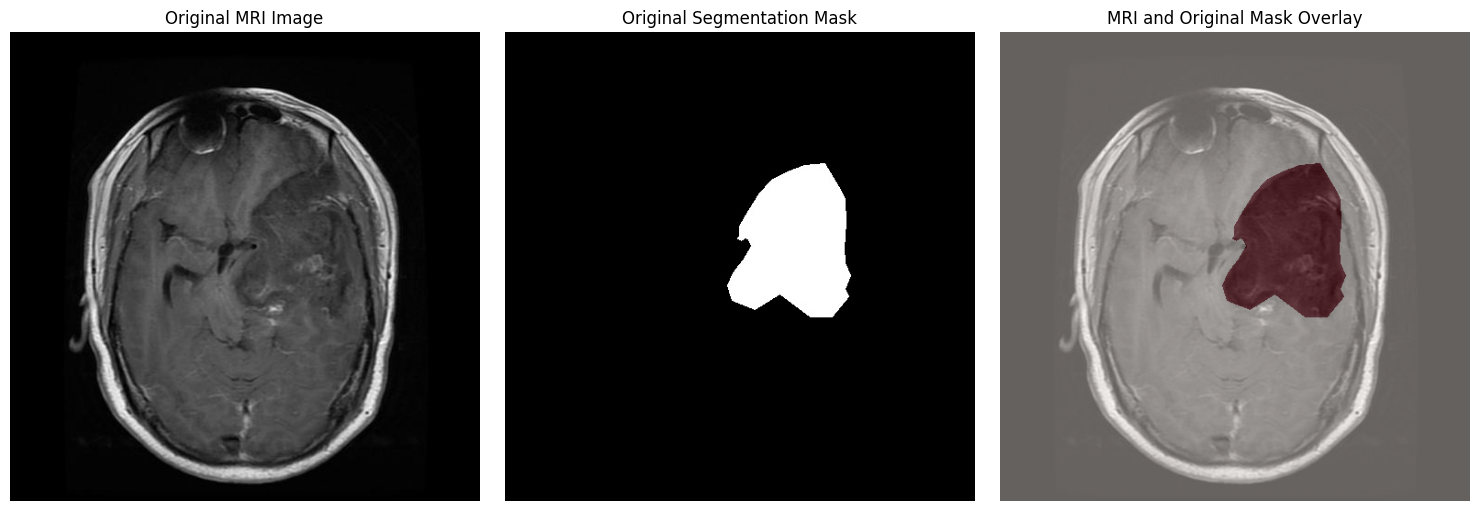

In [17]:
# Step 09: Image and Mask Visual Inspection

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# Select one training image
sample_name = "brisc2025_train_00001_gl_ax_t1"

image_path = segmentation_dir / "train" / "images" / f"{sample_name}.jpg"
mask_path = segmentation_dir / "train" / "masks" / f"{sample_name}.png"

# Load MRI image and mask
image = np.array(Image.open(image_path).convert("RGB"))
mask = np.array(Image.open(mask_path))

# Create visual inspection
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Original MRI Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap="gray")
plt.title("Original Segmentation Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(image)
plt.imshow(mask, cmap="Reds", alpha=0.4)
plt.title("MRI and Original Mask Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

In [18]:
# Step 09: Check Image and Mask Display

print("MRI Image shape:", image.shape)
print("Mask shape:", mask.shape)

print("MRI Image loaded:", image is not None)
print("Mask loaded:", mask is not None)

print("MRI Image size:", image_path.stat().st_size, "bytes")
print("Mask size:", mask_path.stat().st_size, "bytes")

MRI Image shape: (512, 512, 3)
Mask shape: (512, 512)
MRI Image loaded: True
Mask loaded: True
MRI Image size: 25556 bytes
Mask size: 3518 bytes


Step 10 — Save Visual Inspection Image

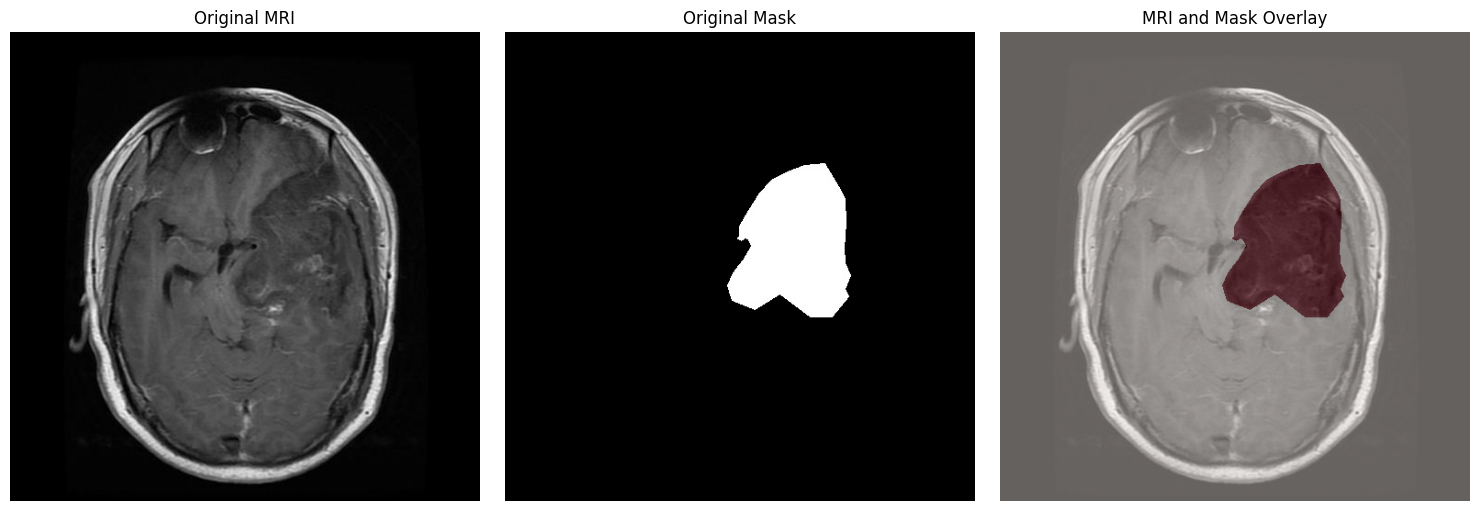

Saved successfully: /content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/BRISC_mask_visual_inspection_step10.png


In [19]:
# Step 10: Save MRI and Mask Visual Inspection

import matplotlib.pyplot as plt

output_path = BASE_DIR / "BRISC_mask_visual_inspection_step10.png"

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap="gray")
plt.title("Original Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(image)
plt.imshow(mask, cmap="Reds", alpha=0.4)
plt.title("MRI and Mask Overlay")
plt.axis("off")

plt.tight_layout()
plt.savefig(output_path, dpi=150, bbox_inches="tight")
plt.show()

print("Saved successfully:", output_path)

Step 10 — Mask Binary Value Verification

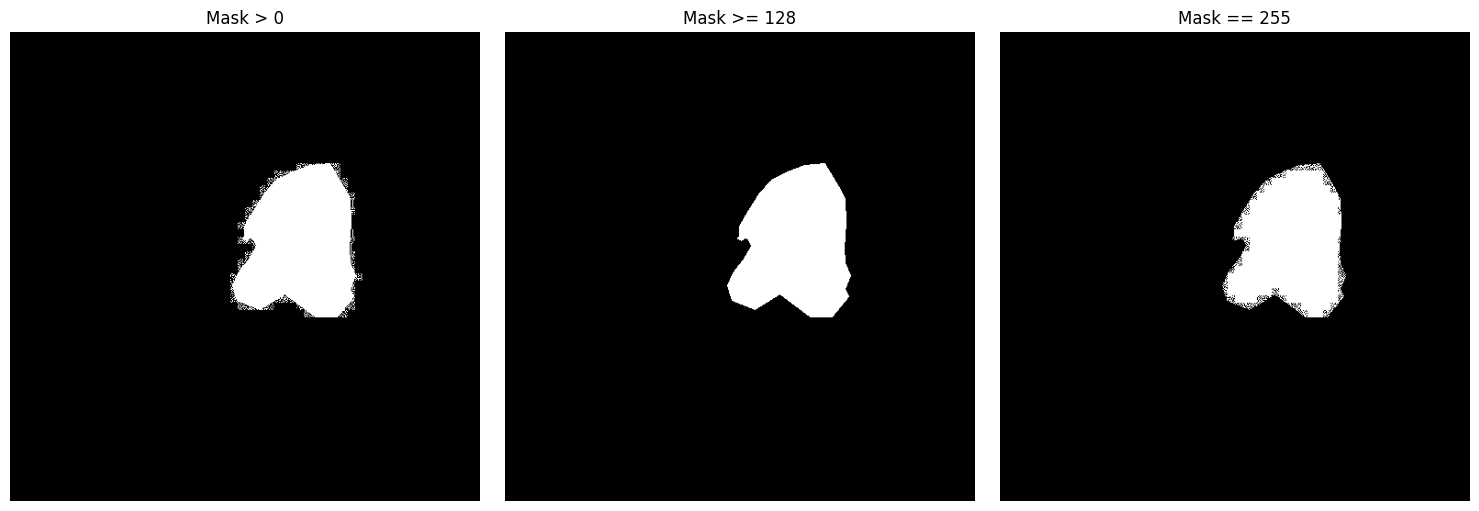

Foreground pixels:
Mask > 0: 17153
Mask >= 128: 16345
Mask == 255: 15527


In [20]:
# Step 10: Mask Binary Value Comparison

import numpy as np
import matplotlib.pyplot as plt

# Create three candidate binary masks
mask_gt0 = (mask > 0).astype(np.uint8)

mask_ge128 = (mask >= 128).astype(np.uint8)

mask_eq255 = (mask == 255).astype(np.uint8)

# Display comparison
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(mask_gt0, cmap="gray")
plt.title("Mask > 0")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask_ge128, cmap="gray")
plt.title("Mask >= 128")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(mask_eq255, cmap="gray")
plt.title("Mask == 255")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Foreground pixels:")
print("Mask > 0:", np.sum(mask_gt0))
print("Mask >= 128:", np.sum(mask_ge128))
print("Mask == 255:", np.sum(mask_eq255))

Step 11 — Multiple MRI and Mask Visual Inspection

Sample: brisc2025_train_03687_pi_ax_t1.jpg
Original mask values: [  0   1   2   3   4   5   7 249 250 251 252 253 254 255]
Foreground pixels: 1918
--------------------------------
Sample: brisc2025_train_00457_gl_co_t1.jpg
Original mask values: [  0   1   2   3   4   5 249 250 251 252 253 254 255]
Foreground pixels: 1639
--------------------------------
Sample: brisc2025_train_00103_gl_ax_t1.jpg
Original mask values: [  0   1   2   3   4   5   6 248 249 250 251 252 253 254 255]
Foreground pixels: 6578
--------------------------------
Sample: brisc2025_train_04105_pi_co_t1.jpg
Original mask values: [  0   1   2   3   4   5   6 248 249 250 251 252 253 254 255]
Foreground pixels: 2296
--------------------------------
Sample: brisc2025_train_01127_gl_sa_t1.jpg
Original mask values: [  0   1   2   3   4   5   7 249 250 251 252 253 254 255]
Foreground pixels: 5159
--------------------------------


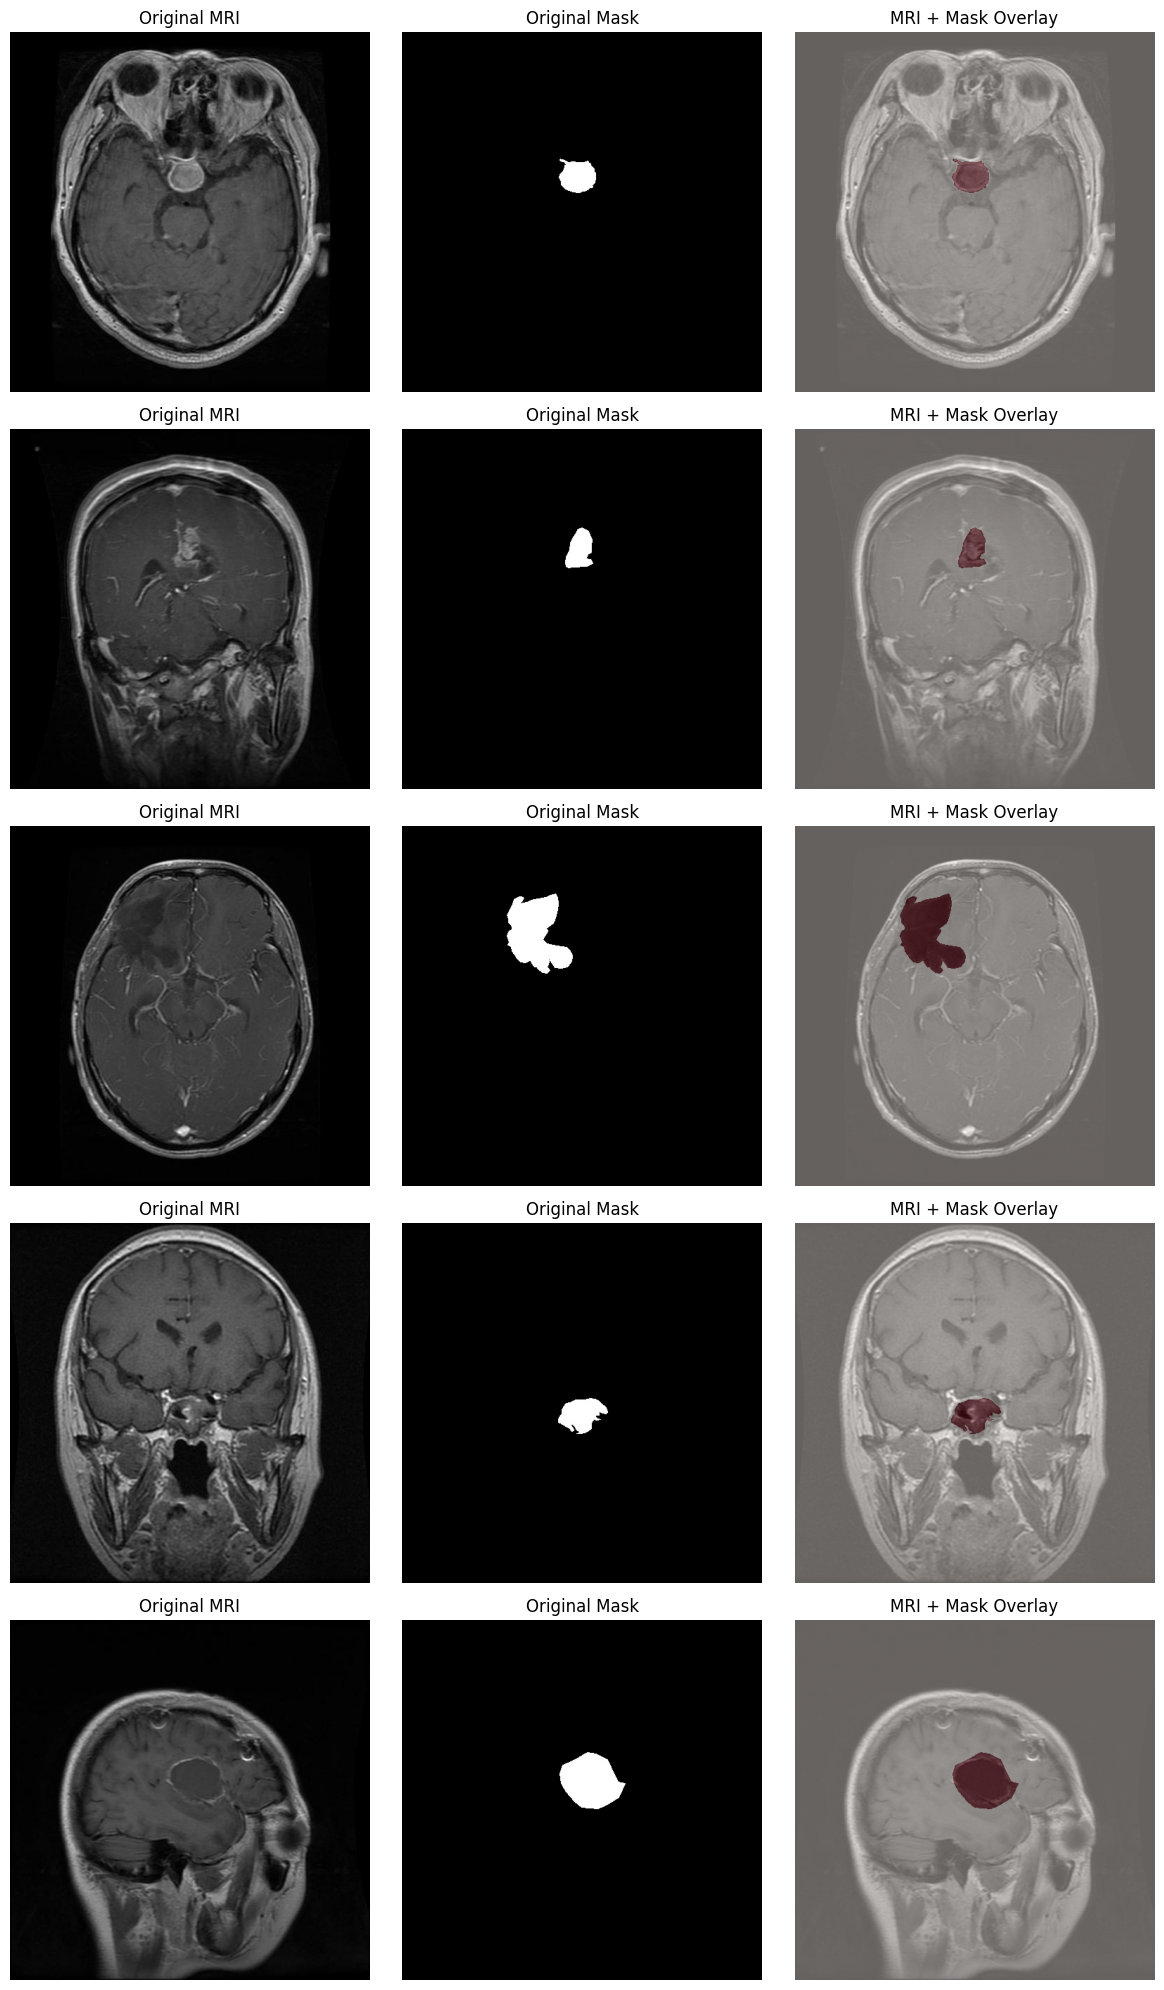

In [21]:
# Step 11: Multiple MRI and Mask Visual Inspection

import random
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# Select 5 random training samples
image_dir = segmentation_dir / "train" / "images"
mask_dir = segmentation_dir / "train" / "masks"

image_files = sorted(image_dir.glob("*.jpg"))

random.seed(42)
sample_files = random.sample(image_files, 5)

# Display MRI, original mask and thresholded mask
fig, axes = plt.subplots(5, 3, figsize=(12, 20))

for i, image_file in enumerate(sample_files):

    mask_file = mask_dir / (image_file.stem + ".png")

    image = np.array(Image.open(image_file).convert("RGB"))
    mask = np.array(Image.open(mask_file))

    binary_mask = (mask >= 128).astype(np.uint8)

    axes[i, 0].imshow(image)
    axes[i, 0].set_title("Original MRI")

    axes[i, 1].imshow(mask, cmap="gray")
    axes[i, 1].set_title("Original Mask")

    axes[i, 2].imshow(image)
    axes[i, 2].imshow(
        binary_mask,
        cmap="Reds",
        alpha=0.4
    )
    axes[i, 2].set_title("MRI + Mask Overlay")

    for j in range(3):
        axes[i, j].axis("off")

    print("Sample:", image_file.name)
    print("Original mask values:", np.unique(mask))
    print("Foreground pixels:", np.sum(binary_mask))
    print("--------------------------------")

plt.tight_layout()
plt.show()

Step 12 — Dataset-Wide Mask Threshold Analysis

In [22]:
# Step 12: Dataset-Wide Mask Threshold Analysis

import numpy as np
from PIL import Image
from pathlib import Path

thresholds = {
    "mask > 0": lambda x: x > 0,
    "mask >= 128": lambda x: x >= 128,
    "mask == 255": lambda x: x == 255
}

for split in ["train", "test"]:

    mask_dir = segmentation_dir / split / "masks"
    mask_files = sorted(mask_dir.glob("*.png"))

    print(f"\n{'='*45}")
    print(f"{split.upper()} DATASET MASK ANALYSIS")
    print(f"{'='*45}")

    print("Total masks:", len(mask_files))

    for threshold_name, threshold_function in thresholds.items():

        foreground_areas = []

        for mask_file in mask_files:

            mask = np.array(Image.open(mask_file).convert("L"))

            binary_mask = threshold_function(mask)

            foreground_pixels = np.count_nonzero(binary_mask)

            foreground_areas.append(foreground_pixels)

        foreground_areas = np.array(foreground_areas)

        empty_masks = np.sum(foreground_areas == 0)

        print(f"\n{threshold_name}")
        print("Total foreground pixels:",
              np.sum(foreground_areas))

        print("Empty masks:", empty_masks)

        print("Minimum foreground pixels:",
              np.min(foreground_areas))

        print("Median foreground pixels:",
              np.median(foreground_areas))

        print("Maximum foreground pixels:",
              np.max(foreground_areas))


TRAIN DATASET MASK ANALYSIS
Total masks: 3933

mask > 0
Total foreground pixels: 18031947
Empty masks: 0
Minimum foreground pixels: 108
Median foreground pixels: 3699.0
Maximum foreground pixels: 76039

mask >= 128
Total foreground pixels: 16221839
Empty masks: 0
Minimum foreground pixels: 23
Median foreground pixels: 3252.0
Maximum foreground pixels: 73320

mask == 255
Total foreground pixels: 14577331
Empty masks: 0
Minimum foreground pixels: 17
Median foreground pixels: 2845.0
Maximum foreground pixels: 70764

TEST DATASET MASK ANALYSIS
Total masks: 860

mask > 0
Total foreground pixels: 3957878
Empty masks: 0
Minimum foreground pixels: 334
Median foreground pixels: 3282.0
Maximum foreground pixels: 67577

mask >= 128
Total foreground pixels: 3582270
Empty masks: 0
Minimum foreground pixels: 214
Median foreground pixels: 2877.0
Maximum foreground pixels: 65890

mask == 255
Total foreground pixels: 3240931
Empty masks: 0
Minimum foreground pixels: 151
Median foreground pixels: 2486.

Step 13 — Binary Mask Conversion Verification

In [23]:
# Step 13: Binary Mask Conversion Verification

import numpy as np
from PIL import Image

# Select one training mask
sample_mask_path = (
    segmentation_dir / "train" / "masks" /
    "brisc2025_train_00001_gl_ax_t1.png"
)

# Load original mask
original_mask = np.array(
    Image.open(sample_mask_path).convert("L")
)

# Convert into binary mask
binary_mask = (original_mask >= 128).astype(np.uint8)

# Verify binary mask
print("Original Mask Values:")
print(np.unique(original_mask))

print("\nBinary Mask Values:")
print(np.unique(binary_mask))

print("\nBackground Pixels:", np.sum(binary_mask == 0))
print("Foreground Pixels:", np.sum(binary_mask == 1))

print("\nBinary Mask Shape:", binary_mask.shape)
print("Data Type:", binary_mask.dtype)

# Final verification
if set(np.unique(binary_mask)).issubset({0, 1}):
    print("\nSUCCESS: Binary mask contains only 0 and 1.")
else:
    print("\nERROR: Unexpected pixel values found.")

Original Mask Values:
[  0   1   2   3   4   5   6   7 248 249 250 251 252 253 254 255]

Binary Mask Values:
[0 1]

Background Pixels: 245799
Foreground Pixels: 16345

Binary Mask Shape: (512, 512)
Data Type: uint8

SUCCESS: Binary mask contains only 0 and 1.


Step 14 — Sample Image and Mask Resizing

Original Image Shape: (512, 512, 3)
Resized Image Shape: (256, 256, 3)
Original Mask Shape: (512, 512)
Resized Mask Shape: (256, 256)
Resized Mask Values: [0 1]


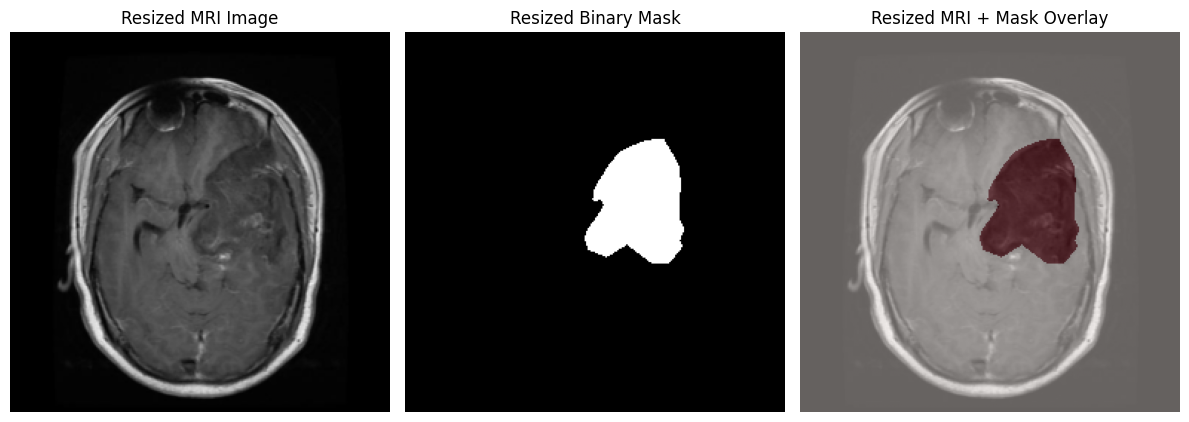

In [24]:
# Step 14: Sample Image and Mask Resizing

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Step 1: Select sample image and mask
sample_name = "brisc2025_train_00001_gl_ax_t1"

image_path = (
    segmentation_dir / "train" / "images" /
    f"{sample_name}.jpg"
)

mask_path = (
    segmentation_dir / "train" / "masks" /
    f"{sample_name}.png"
)

# Step 2: Load original image and mask
image = Image.open(image_path).convert("RGB")
mask = Image.open(mask_path).convert("L")

# Step 3: Convert original mask into binary mask
mask_array = np.array(mask)
binary_mask = (mask_array >= 128).astype(np.uint8)

binary_mask_image = Image.fromarray(binary_mask)

# Step 4: Resize image using Bilinear interpolation
resized_image = image.resize(
    (256, 256),
    Image.Resampling.BILINEAR
)

# Step 5: Resize mask using Nearest Neighbor
resized_mask = binary_mask_image.resize(
    (256, 256),
    Image.Resampling.NEAREST
)

# Step 6: Convert resized results into arrays
resized_image_array = np.array(resized_image)
resized_mask_array = np.array(resized_mask)

# Step 7: Print verification results
print("Original Image Shape:", np.array(image).shape)
print("Resized Image Shape:", resized_image_array.shape)

print("Original Mask Shape:", binary_mask.shape)
print("Resized Mask Shape:", resized_mask_array.shape)

print("Resized Mask Values:", np.unique(resized_mask_array))

# Step 8: Visualize resized results
plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(resized_image_array)
plt.title("Resized MRI Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(resized_mask_array, cmap="gray")
plt.title("Resized Binary Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(resized_image_array)
plt.imshow(resized_mask_array, cmap="Reds", alpha=0.4)
plt.title("Resized MRI + Mask Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

**Step** 15 — MRI Image Normalization

In [25]:
# Step 15: MRI Image Normalization

import numpy as np

# Step 1: Convert resized image into float32
normalized_image = resized_image_array.astype(np.float32)

# Step 2: Normalize pixel values from 0-255 to 0-1
normalized_image = normalized_image / 255.0

# Step 3: Verify normalization
print("Original Image Data Type:", resized_image_array.dtype)

print("Normalized Image Data Type:", normalized_image.dtype)

print("Original Image Minimum:", resized_image_array.min())
print("Original Image Maximum:", resized_image_array.max())

print("Normalized Image Minimum:", normalized_image.min())
print("Normalized Image Maximum:", normalized_image.max())

print("Normalized Image Shape:", normalized_image.shape)

# Step 4: Verify mask separately
print("\nMask Values:", np.unique(resized_mask_array))
print("Mask Data Type:", resized_mask_array.dtype)

Original Image Data Type: uint8
Normalized Image Data Type: float32
Original Image Minimum: 0
Original Image Maximum: 235
Normalized Image Minimum: 0.0
Normalized Image Maximum: 0.92156863
Normalized Image Shape: (256, 256, 3)

Mask Values: [0 1]
Mask Data Type: uint8


Step 16 — Create Preprocessing Output Folders

In [27]:
# Step 16: Create Preprocessing Output Folders

from pathlib import Path

# Step 1: Define output directory
OUTPUT_DIR = BASE_DIR / "BRISC_preprocessed_256_v2"

# Step 2: Prevent accidental overwriting
if OUTPUT_DIR.exists():
    raise FileExistsError(
        f"Output folder already exists: {OUTPUT_DIR}"
    )

# Step 3: Create Train and Test folders
for split in ["train", "test"]:

    (OUTPUT_DIR / split / "images").mkdir(
        parents=True,
        exist_ok=True
    )

    (OUTPUT_DIR / split / "masks").mkdir(
        parents=True,
        exist_ok=True
    )

# Step 4: Verify folder creation
print("Output folder created successfully!")

for split in ["train", "test"]:

    print(f"\n{split.upper()}")

    print("Images:",
          OUTPUT_DIR / split / "images")

    print("Masks:",
          OUTPUT_DIR / split / "masks")

FileExistsError: Output folder already exists: /content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/BRISC_preprocessed_256_v2

In [28]:
# Step 16: Verify Existing Preprocessing Output Folders

from pathlib import Path

OUTPUT_DIR = BASE_DIR / "BRISC_preprocessed_256_v2"

print("Output folder exists:", OUTPUT_DIR.exists())

for split in ["train", "test"]:

    print(f"\n{split.upper()}")

    print(
        "Images folder exists:",
        (OUTPUT_DIR / split / "images").exists()
    )

    print(
        "Masks folder exists:",
        (OUTPUT_DIR / split / "masks").exists()
    )

Output folder exists: True

TRAIN
Images folder exists: True
Masks folder exists: True

TEST
Images folder exists: True
Masks folder exists: True


Step 17 — Mask Encoding Verification

In [29]:
from PIL import Image
import numpy as np

mask_path = (
    BRISC_ROOT
    / "segmentation_task"
    / "train"
    / "masks"
    / "brisc2025_train_00001_gl_ax_t1.png"
)

mask_image = Image.open(mask_path)
mask_array = np.array(mask_image)

print("Mask file:", mask_path.name)
print("PIL Mode:", mask_image.mode)
print("Image Size:", mask_image.size)
print("Array Shape:", mask_array.shape)
print("Data Type:", mask_array.dtype)
print("Unique Pixel Values:")
print(np.unique(mask_array))

print("\nMask Metadata:")
print(mask_image.info)

print("\nPixel Value Counts:")
values, counts = np.unique(
    mask_array,
    return_counts=True
)

for value, count in zip(values, counts):
    print(f"{value}: {count}")

Mask file: brisc2025_train_00001_gl_ax_t1.png
PIL Mode: L
Image Size: (512, 512)
Array Shape: (512, 512)
Data Type: uint8
Unique Pixel Values:
[  0   1   2   3   4   5   6   7 248 249 250 251 252 253 254 255]

Mask Metadata:
{}

Pixel Value Counts:
0: 244991
1: 398
2: 227
3: 117
4: 39
5: 20
6: 6
7: 1
248: 2
249: 2
250: 26
251: 44
252: 111
253: 220
254: 413
255: 15527


Step 17 — Compare Original Mask and Binary Masks

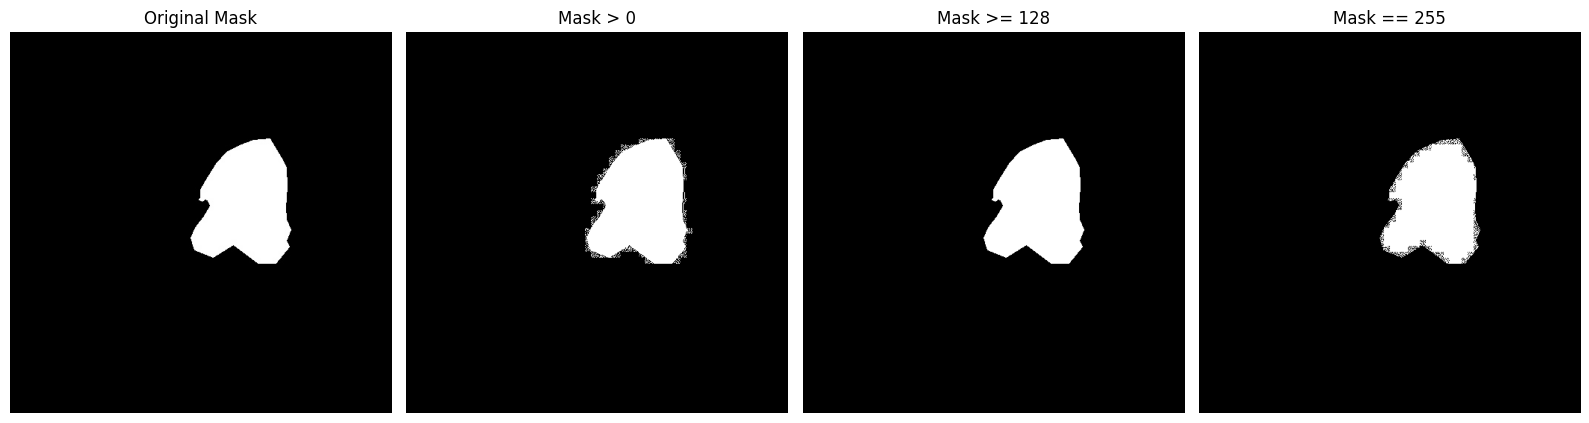

Original Mask Shape: (512, 512)

Foreground Pixel Counts:
Mask > 0: 17153
Mask >= 128: 16345
Mask == 255: 15527

Unique Values:
Mask > 0: [0 1]
Mask >= 128: [0 1]
Mask == 255: [0 1]


In [30]:
# Step 17: Original and Binary Mask Comparison

import numpy as np
import matplotlib.pyplot as plt

# Original mask
mask = mask_array

# Three candidate binary masks
mask_gt0 = (mask > 0).astype(np.uint8)

mask_ge128 = (mask >= 128).astype(np.uint8)

mask_eq255 = (mask == 255).astype(np.uint8)

# Display all masks
fig, axes = plt.subplots(1, 4, figsize=(16, 5))

axes[0].imshow(mask, cmap="gray")
axes[0].set_title("Original Mask")

axes[1].imshow(mask_gt0, cmap="gray")
axes[1].set_title("Mask > 0")

axes[2].imshow(mask_ge128, cmap="gray")
axes[2].set_title("Mask >= 128")

axes[3].imshow(mask_eq255, cmap="gray")
axes[3].set_title("Mask == 255")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Foreground pixel comparison
print("Original Mask Shape:", mask.shape)

print("\nForeground Pixel Counts:")
print("Mask > 0:", np.sum(mask_gt0))
print("Mask >= 128:", np.sum(mask_ge128))
print("Mask == 255:", np.sum(mask_eq255))

print("\nUnique Values:")
print("Mask > 0:", np.unique(mask_gt0))
print("Mask >= 128:", np.unique(mask_ge128))
print("Mask == 255:", np.unique(mask_eq255))

Step 18 — Analyze Mask Pixel Distribution

In [31]:
# Step 18: Analyze Multiple BRISC Masks

import numpy as np
from PIL import Image
from pathlib import Path
import pandas as pd

mask_dir = segmentation_dir / "train" / "masks"

mask_files = sorted(mask_dir.glob("*.png"))

print("Total training masks:", len(mask_files))

# Select 100 masks for initial analysis
sample_files = mask_files[:100]

results = []

for file in sample_files:

    mask = np.array(Image.open(file).convert("L"))

    results.append({
        "filename": file.name,
        "min_value": int(mask.min()),
        "max_value": int(mask.max()),
        "unique_values": len(np.unique(mask)),
        "pixels_0": int(np.sum(mask == 0)),
        "pixels_1_to_7": int(np.sum((mask >= 1) & (mask <= 7))),
        "pixels_248_to_255": int(np.sum((mask >= 248) & (mask <= 255))),
        "pixels_gt0": int(np.sum(mask > 0)),
        "pixels_ge128": int(np.sum(mask >= 128))
    })

df_mask_analysis = pd.DataFrame(results)

print("\nFirst 10 masks:")
display(df_mask_analysis.head(10))

print("\nSummary:")
display(df_mask_analysis.describe())

print("\nMasks with unexpected pixel ranges:")
print(
    df_mask_analysis[
        (df_mask_analysis["pixels_1_to_7"] > 0) |
        (df_mask_analysis["pixels_248_to_255"] == 0)
    ].shape[0]
)

Total training masks: 3933

First 10 masks:


,filename,min_value,max_value,unique_values,pixels_0,pixels_1_to_7,pixels_248_to_255,pixels_gt0,pixels_ge128
0,brisc2025_train_00001_gl_ax_t1.png,0,255,16,244991,808,16345,17153,16345
1,brisc2025_train_00002_gl_ax_t1.png,0,255,17,245622,724,15797,16522,15797
2,brisc2025_train_00003_gl_ax_t1.png,0,255,14,259002,400,2742,3142,2742
3,brisc2025_train_00004_gl_ax_t1.png,0,255,16,259482,369,2293,2662,2293
4,brisc2025_train_00005_gl_ax_t1.png,0,255,15,258014,544,3586,4130,3586
5,brisc2025_train_00006_gl_ax_t1.png,0,255,15,258359,346,3439,3785,3439
6,brisc2025_train_00007_gl_ax_t1.png,0,255,16,252897,659,8588,9247,8588
7,brisc2025_train_00008_gl_ax_t1.png,0,255,14,251684,584,9876,10460,9876
8,brisc2025_train_00009_gl_ax_t1.png,0,255,15,258215,370,3559,3929,3559
9,brisc2025_train_00010_gl_ax_t1.png,0,255,14,256855,584,4705,5289,4705



Summary:


,min_value,max_value,unique_values,pixels_0,pixels_1_to_7,pixels_248_to_255,pixels_gt0,pixels_ge128
count,100.0,100.0,100.00000,100.000000,100.000000,100.000000,100.000000,100.000000
mean,0.0,255.0,14.96000,255909.200000,515.720000,5719.020000,6234.800000,5719.030000
std,0.0,0.0,1.10023,4846.114801,238.130305,4625.039889,4846.114801,4625.038229
min,0.0,255.0,12.00000,241459.000000,152.000000,416.000000,579.000000,416.000000
25%,0.0,255.0,14.00000,253320.000000,357.000000,2604.250000,2948.250000,2604.250000
50%,0.0,255.0,15.00000,257218.500000,486.500000,4327.500000,4925.500000,4327.500000
75%,0.0,255.0,16.00000,259195.750000,660.250000,8127.000000,8824.000000,8127.000000
max,0.0,255.0,17.00000,261565.000000,1268.000000,19416.000000,20685.000000,19416.000000



Masks with unexpected pixel ranges:
100


Step 19: Analyze Mask Pixel Intensity Distribution

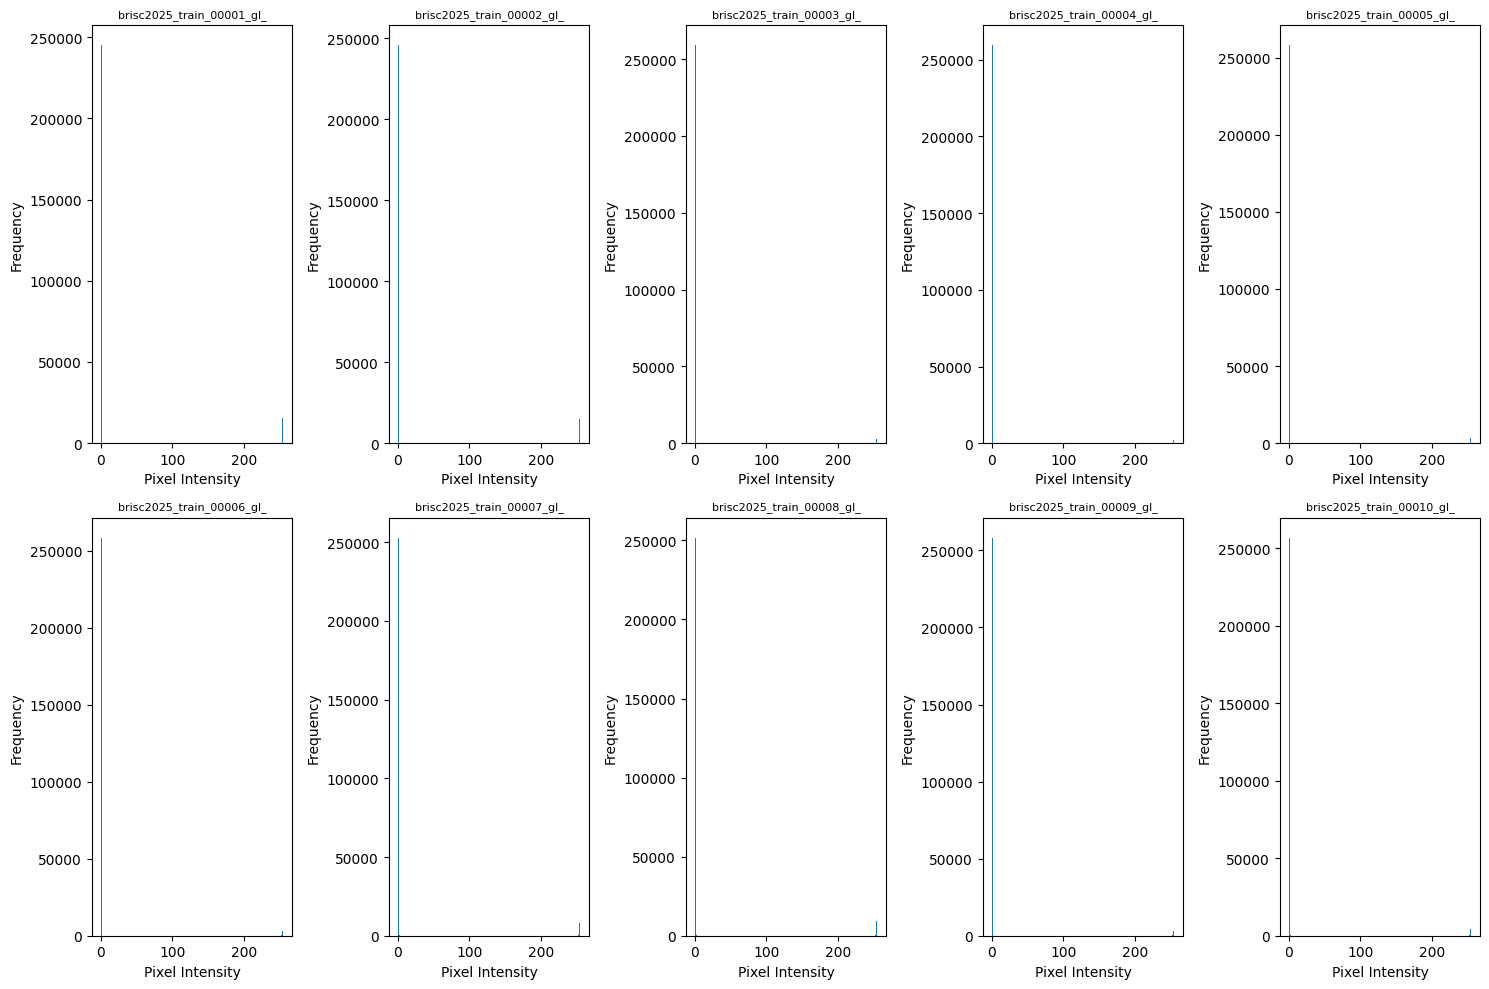

In [32]:
# Step 19: Analyze Mask Pixel Intensity Distribution

import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

mask_dir = segmentation_dir / "train" / "masks"
mask_files = sorted(mask_dir.glob("*.png"))

# Select 10 masks for detailed analysis
sample_files = mask_files[:10]

plt.figure(figsize=(15, 10))

for i, file in enumerate(sample_files):

    mask = np.array(Image.open(file).convert("L"))

    plt.subplot(2, 5, i + 1)

    plt.hist(mask.flatten(), bins=256, range=(0, 255))

    plt.title(file.name[:25], fontsize=8)
    plt.xlabel("Pixel Intensity")
    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

Step 19 (Alternative): Text-Based Pixel Distribution

In [33]:
# Step 19: Text-Based Pixel Distribution

import numpy as np
from PIL import Image

mask_dir = segmentation_dir / "train" / "masks"
mask_files = sorted(mask_dir.glob("*.png"))

sample_files = mask_files[:10]

for file in sample_files:

    mask = np.array(Image.open(file).convert("L"))

    print("\nMask:", file.name)
    print("Shape:", mask.shape)

    values, counts = np.unique(mask, return_counts=True)

    print("Unique values:", values)
    print("Pixel counts:", counts)

    print("Pixels 0:", np.sum(mask == 0))
    print("Pixels 1-7:", np.sum((mask >= 1) & (mask <= 7)))
    print("Pixels 8-247:", np.sum((mask >= 8) & (mask <= 247)))
    print("Pixels 248-255:", np.sum((mask >= 248) & (mask <= 255)))


Mask: brisc2025_train_00001_gl_ax_t1.png
Shape: (512, 512)
Unique values: [  0   1   2   3   4   5   6   7 248 249 250 251 252 253 254 255]
Pixel counts: [244991    398    227    117     39     20      6      1      2      2
     26     44    111    220    413  15527]
Pixels 0: 244991
Pixels 1-7: 808
Pixels 8-247: 0
Pixels 248-255: 16345

Mask: brisc2025_train_00002_gl_ax_t1.png
Shape: (512, 512)
Unique values: [  0   1   2   3   4   5   6   7   8 248 249 250 251 252 253 254 255]
Pixel counts: [245622    366    187    119     31     17      3      1      1      2
      3     21     39    112    240    410  14970]
Pixels 0: 245622
Pixels 1-7: 724
Pixels 8-247: 1
Pixels 248-255: 15797

Mask: brisc2025_train_00003_gl_ax_t1.png
Shape: (512, 512)
Unique values: [  0   1   2   3   4   5   6 248 250 251 252 253 254 255]
Pixel counts: [259002    187    119     55     30      8      1      1      3     13
     46     80    158   2441]
Pixels 0: 259002
Pixels 1-7: 400
Pixels 8-247: 0
Pixels 248

Step 20: Verify Binary Mask Candidates

In [34]:
# Step 20: Compare Binary Mask Candidates

import numpy as np
from PIL import Image
import pandas as pd

mask_dir = segmentation_dir / "train" / "masks"
mask_files = sorted(mask_dir.glob("*.png"))

results = []

for file in mask_files:

    mask = np.array(Image.open(file).convert("L"))

    results.append({
        "filename": file.name,
        "gt0": int(np.sum(mask > 0)),
        "ge128": int(np.sum(mask >= 128)),
        "eq255": int(np.sum(mask == 255)),
        "low_values": int(np.sum((mask >= 1) & (mask <= 7))),
        "high_values": int(np.sum((mask >= 248) & (mask <= 255)))
    })

df_candidates = pd.DataFrame(results)

print("Total masks:", len(df_candidates))

print("\nCandidate comparison:")
display(df_candidates[["gt0", "ge128", "eq255"]].describe())

print("\nLow and high intensity summary:")
display(df_candidates[["low_values", "high_values"]].describe())

print("\nMasks with pixels between 8 and 247:")
print(
    sum(
        np.sum(
            np.array(Image.open(file).convert("L"))[
                (np.array(Image.open(file).convert("L")) >= 8) &
                (np.array(Image.open(file).convert("L")) <= 247)
            ]
        ) > 0
        for file in mask_files
    )
)

Total masks: 3933

Candidate comparison:


,gt0,ge128,eq255
count,3933.000000,3933.000000,3933.000000
mean,4584.781846,4124.545894,3706.415205
std,3719.299602,3554.758050,3388.268802
min,108.000000,23.000000,17.000000
25%,2208.000000,1865.000000,1574.000000
50%,3699.000000,3252.000000,2845.000000
75%,5829.000000,5266.000000,4762.000000
max,76039.000000,73320.000000,70764.000000



Low and high intensity summary:


,low_values,high_values
count,3933.000000,3933.000000
mean,460.209255,4124.515637
std,196.713463,3554.750993
min,76.000000,23.000000
25%,317.000000,1865.000000
50%,436.000000,3252.000000
75%,574.000000,5266.000000
max,2719.000000,73320.000000



Masks with pixels between 8 and 247:
216


Step 21: Identify Masks Containing Intermediate Values

In [35]:
# Step 21: Identify Intermediate Pixel Values

import numpy as np
from PIL import Image
import pandas as pd

mask_dir = segmentation_dir / "train" / "masks"
mask_files = sorted(mask_dir.glob("*.png"))

intermediate_results = []

for file in mask_files:

    mask = np.array(Image.open(file).convert("L"))

    intermediate_count = int(
        np.sum((mask >= 8) & (mask <= 247))
    )

    if intermediate_count > 0:

        intermediate_results.append({
            "filename": file.name,
            "intermediate_pixels": intermediate_count,
            "unique_values": len(np.unique(mask)),
            "min_value": int(mask.min()),
            "max_value": int(mask.max())
        })

df_intermediate = pd.DataFrame(intermediate_results)

print("Masks containing intermediate values:",
      len(df_intermediate))

print("\nFirst 20 masks:")
display(df_intermediate.head(20))

print("\nIntermediate pixel count summary:")
display(df_intermediate["intermediate_pixels"].describe())

print("\nTop 10 masks by intermediate pixel count:")
display(
    df_intermediate.sort_values(
        "intermediate_pixels",
        ascending=False
    ).head(10)
)

Masks containing intermediate values: 216

First 20 masks:


,filename,intermediate_pixels,unique_values,min_value,max_value
0,brisc2025_train_00002_gl_ax_t1.png,1,17,0,255
1,brisc2025_train_00044_gl_ax_t1.png,1,16,0,255
2,brisc2025_train_00045_gl_ax_t1.png,1,16,0,255
3,brisc2025_train_00052_gl_ax_t1.png,1,15,0,255
4,brisc2025_train_00069_gl_ax_t1.png,1,17,0,255
5,brisc2025_train_00083_gl_ax_t1.png,1,17,0,255
6,brisc2025_train_00140_gl_ax_t1.png,1,17,0,255
7,brisc2025_train_00151_gl_ax_t1.png,1,17,0,255
8,brisc2025_train_00156_gl_ax_t1.png,1,17,0,255
9,brisc2025_train_00217_gl_ax_t1.png,1,15,0,255



Intermediate pixel count summary:


,intermediate_pixels
count,216.000000
mean,1.037037
std,0.212446
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,3.000000



Top 10 masks by intermediate pixel count:


,filename,intermediate_pixels,unique_values,min_value,max_value
181,brisc2025_train_04022_pi_co_t1.png,3,18,0,255
22,brisc2025_train_00504_gl_co_t1.png,2,17,0,255
64,brisc2025_train_01385_me_ax_t1.png,2,17,0,255
42,brisc2025_train_01018_gl_sa_t1.png,2,16,0,255
124,brisc2025_train_02066_me_sa_t1.png,2,17,0,255
149,brisc2025_train_02416_me_sa_t1.png,2,18,0,255
102,brisc2025_train_01777_me_co_t1.png,2,15,0,255
0,brisc2025_train_00002_gl_ax_t1.png,1,17,0,255
7,brisc2025_train_00151_gl_ax_t1.png,1,17,0,255
8,brisc2025_train_00156_gl_ax_t1.png,1,17,0,255


Step 22: Inspect Intermediate Pixel Values

In [36]:
# Step 22: Inspect Intermediate Pixel Values

import numpy as np
from PIL import Image
from collections import Counter

mask_dir = segmentation_dir / "train" / "masks"
mask_files = sorted(mask_dir.glob("*.png"))

intermediate_values = Counter()
intermediate_locations = []

for file in mask_files:

    mask = np.array(Image.open(file).convert("L"))

    positions = np.where((mask >= 8) & (mask <= 247))

    for y, x in zip(positions[0], positions[1]):

        value = int(mask[y, x])

        intermediate_values[value] += 1

        intermediate_locations.append({
            "filename": file.name,
            "x": int(x),
            "y": int(y),
            "pixel_value": value
        })

print("Intermediate pixel value distribution:")
print(intermediate_values)

print("\nTotal intermediate pixels:",
      sum(intermediate_values.values()))

print("\nFirst 20 intermediate pixel locations:")
for item in intermediate_locations[:20]:
    print(item)

Intermediate pixel value distribution:
Counter({247: 110, 8: 99, 246: 9, 9: 5, 10: 1})

Total intermediate pixels: 224

First 20 intermediate pixel locations:
{'filename': 'brisc2025_train_00002_gl_ax_t1.png', 'x': 348, 'y': 169, 'pixel_value': 8}
{'filename': 'brisc2025_train_00044_gl_ax_t1.png', 'x': 321, 'y': 186, 'pixel_value': 8}
{'filename': 'brisc2025_train_00045_gl_ax_t1.png', 'x': 339, 'y': 265, 'pixel_value': 247}
{'filename': 'brisc2025_train_00052_gl_ax_t1.png', 'x': 260, 'y': 302, 'pixel_value': 8}
{'filename': 'brisc2025_train_00069_gl_ax_t1.png', 'x': 196, 'y': 137, 'pixel_value': 8}
{'filename': 'brisc2025_train_00083_gl_ax_t1.png', 'x': 278, 'y': 233, 'pixel_value': 8}
{'filename': 'brisc2025_train_00140_gl_ax_t1.png', 'x': 196, 'y': 245, 'pixel_value': 8}
{'filename': 'brisc2025_train_00151_gl_ax_t1.png', 'x': 252, 'y': 89, 'pixel_value': 8}
{'filename': 'brisc2025_train_00156_gl_ax_t1.png', 'x': 276, 'y': 113, 'pixel_value': 8}
{'filename': 'brisc2025_train_00217_gl_

Step 23: Inspect Neighboring Pixels

In [37]:
# Step 23: Inspect Neighbouring Pixel Values

import numpy as np
from PIL import Image
from collections import Counter

mask_dir = segmentation_dir / "train" / "masks"
mask_files = sorted(mask_dir.glob("*.png"))

neighbor_summary = Counter()

for file in mask_files:

    mask = np.array(Image.open(file).convert("L"))

    ys, xs = np.where((mask >= 8) & (mask <= 247))

    for y, x in zip(ys, xs):

        y1 = max(0, y - 1)
        y2 = min(mask.shape[0], y + 2)

        x1 = max(0, x - 1)
        x2 = min(mask.shape[1], x + 2)

        neighborhood = mask[y1:y2, x1:x2]

        # Remove the center pixel
        neighbors = neighborhood.flatten()
        center_index = (y - y1) * neighborhood.shape[1] + (x - x1)
        neighbors = np.delete(neighbors, center_index)

        neighbor_summary["background_0"] += int(
            np.sum(neighbors == 0)
        )

        neighbor_summary["foreground_248_255"] += int(
            np.sum((neighbors >= 248) & (neighbors <= 255))
        )

        neighbor_summary["low_1_7"] += int(
            np.sum((neighbors >= 1) & (neighbors <= 7))
        )

        neighbor_summary["intermediate_8_247"] += int(
            np.sum((neighbors >= 8) & (neighbors <= 247))
        )

print("Neighbor pixel summary:")
for key, value in neighbor_summary.items():
    print(key, ":", value)

Neighbor pixel summary:
background_0 : 669
foreground_248_255 : 962
low_1_7 : 161
intermediate_8_247 : 0


Step 24: Verify the Original BRISC Mask Documentation

In [38]:
# Step 24: Search BRISC README for Mask Information

readme_path = BRISC_ROOT / "README.md"

with open(readme_path, "r", encoding="utf-8") as file:
    readme_text = file.read()

keywords = [
    "binary",
    "mask",
    "segmentation",
    "pixel",
    "annotation",
    "label",
    "threshold",
    "resize"
]

for keyword in keywords:

    print("\n" + "=" * 50)
    print("KEYWORD:", keyword)

    matching_lines = [
        line.strip()
        for line in readme_text.splitlines()
        if keyword.lower() in line.lower()
    ]

    if matching_lines:
        for line in matching_lines:
            print(line)
    else:
        print("No matching line found.")


KEYWORD: binary
- Segmentation folders contain paired MRI `images/` and corresponding binary `masks/`.

KEYWORD: mask
BRISC is designed to address common shortcomings in existing public brain MRI collections (e.g., class imbalance, limited tumor types, and annotation inconsistency). It provides high-quality, physician-validated pixel-level masks and a balanced multi-class classification split, suitable for benchmarking segmentation and classification algorithms as well as multi-task learning research.
- Pixel-wise segmentation masks reviewed by radiologists
- Clean, stratified train/test splits and aligned image–mask filenames
│  └─ masks/
- Segmentation folders contain paired MRI `images/` and corresponding binary `masks/`.
- Image and mask filenames are identical except for file extension (images: `.jpg`, masks: `.png`).
**Corresponding mask filename:** `brisc2025_test_00010_gl_ax_t1.png` (same basename, different extension)

KEYWORD: segmentation
> **BRISC** (BRain tumor Image Segm

Step 25: Check Binary Conversion on Training Samples

In [39]:
# Step 25: Test Binary Mask Conversion

import numpy as np
from PIL import Image
import pandas as pd

mask_dir = segmentation_dir / "train" / "masks"
mask_files = sorted(mask_dir.glob("*.png"))

results = []

for file in mask_files[:10]:

    original_mask = np.array(
        Image.open(file).convert("L")
    )

    binary_mask = (
        original_mask >= 128
    ).astype(np.uint8)

    results.append({
        "filename": file.name,
        "original_shape": original_mask.shape,
        "binary_shape": binary_mask.shape,
        "binary_values": np.unique(binary_mask).tolist(),
        "background_pixels": int(np.sum(binary_mask == 0)),
        "foreground_pixels": int(np.sum(binary_mask == 1))
    })

df_binary_test = pd.DataFrame(results)

display(df_binary_test)

,filename,original_shape,binary_shape,binary_values,background_pixels,foreground_pixels
0,brisc2025_train_00001_gl_ax_t1.png,"(512, 512)","(512, 512)","[0, 1]",245799,16345
1,brisc2025_train_00002_gl_ax_t1.png,"(512, 512)","(512, 512)","[0, 1]",246347,15797
2,brisc2025_train_00003_gl_ax_t1.png,"(512, 512)","(512, 512)","[0, 1]",259402,2742
3,brisc2025_train_00004_gl_ax_t1.png,"(512, 512)","(512, 512)","[0, 1]",259851,2293
4,brisc2025_train_00005_gl_ax_t1.png,"(512, 512)","(512, 512)","[0, 1]",258558,3586
5,brisc2025_train_00006_gl_ax_t1.png,"(512, 512)","(512, 512)","[0, 1]",258705,3439
6,brisc2025_train_00007_gl_ax_t1.png,"(512, 512)","(512, 512)","[0, 1]",253556,8588
7,brisc2025_train_00008_gl_ax_t1.png,"(512, 512)","(512, 512)","[0, 1]",252268,9876
8,brisc2025_train_00009_gl_ax_t1.png,"(512, 512)","(512, 512)","[0, 1]",258585,3559
9,brisc2025_train_00010_gl_ax_t1.png,"(512, 512)","(512, 512)","[0, 1]",257439,4705


Step 26: Validate Binary Conversion on the Complete Dataset

In [40]:
# Step 26: Validate Binary Conversion on All Masks

import numpy as np
from PIL import Image
from pathlib import Path

splits = ["train", "test"]

for split in splits:

    mask_dir = segmentation_dir / split / "masks"
    mask_files = sorted(mask_dir.glob("*.png"))

    total_masks = len(mask_files)
    invalid_masks = 0
    empty_masks = 0
    total_foreground = 0
    total_background = 0
    shape_errors = 0

    for file in mask_files:

        original_mask = np.array(
            Image.open(file).convert("L")
        )

        binary_mask = (
            original_mask >= 128
        ).astype(np.uint8)

        if not np.array_equal(
            np.unique(binary_mask), [0, 1]
        ):
            invalid_masks += 1

        foreground = int(np.sum(binary_mask == 1))
        background = int(np.sum(binary_mask == 0))

        if foreground == 0:
            empty_masks += 1

        if binary_mask.shape != original_mask.shape:
            shape_errors += 1

        total_foreground += foreground
        total_background += background

    print("\n==========", split.upper(), "==========")
    print("Total masks:", total_masks)
    print("Invalid binary masks:", invalid_masks)
    print("Empty masks:", empty_masks)
    print("Shape errors:", shape_errors)
    print("Total foreground pixels:", total_foreground)
    print("Total background pixels:", total_background)


========== TRAIN ==========
Total masks: 3933
Invalid binary masks: 0
Empty masks: 0
Shape errors: 0
Total foreground pixels: 16221839
Total background pixels: 997960182

========== TEST ==========
Total masks: 860
Invalid binary masks: 0
Empty masks: 0
Shape errors: 0
Total foreground pixels: 3582270
Total background pixels: 205036656


Step 27: Test Image and Mask Preprocessing

In [41]:
# Step 27: Test Image and Mask Preprocessing

import numpy as np
from PIL import Image
import pandas as pd

from pathlib import Path

IMAGE_SIZE = (256, 256)

image_dir = segmentation_dir / "train" / "images"
mask_dir = segmentation_dir / "train" / "masks"

image_files = sorted(image_dir.glob("*.jpg"))

results = []

for image_path in image_files[:10]:

    mask_path = mask_dir / (image_path.stem + ".png")

    # Load MRI image
    image = Image.open(image_path).convert("RGB")

    # Resize image
    image = image.resize(
        IMAGE_SIZE,
        Image.Resampling.BILINEAR
    )

    # Normalize image
    image_array = np.array(image, dtype=np.float32) / 255.0

    # Load original mask
    mask = Image.open(mask_path).convert("L")

    # Provisional binary conversion
    mask_array = (
        np.array(mask) >= 128
    ).astype(np.uint8)

    # Resize binary mask using nearest neighbor
    binary_mask = Image.fromarray(mask_array)

    binary_mask = binary_mask.resize(
        IMAGE_SIZE,
        Image.Resampling.NEAREST
    )

    binary_mask_array = np.array(binary_mask)

    results.append({
        "filename": image_path.name,
        "image_shape": image_array.shape,
        "image_dtype": str(image_array.dtype),
        "image_min": float(image_array.min()),
        "image_max": float(image_array.max()),
        "mask_shape": binary_mask_array.shape,
        "mask_values": np.unique(binary_mask_array).tolist()
    })

df_step27 = pd.DataFrame(results)

display(df_step27)

,filename,image_shape,image_dtype,image_min,image_max,mask_shape,mask_values
0,brisc2025_train_00001_gl_ax_t1.jpg,"(256, 256, 3)",float32,0.0,0.921569,"(256, 256)","[0, 1]"
1,brisc2025_train_00002_gl_ax_t1.jpg,"(256, 256, 3)",float32,0.0,0.925490,"(256, 256)","[0, 1]"
2,brisc2025_train_00003_gl_ax_t1.jpg,"(256, 256, 3)",float32,0.0,0.847059,"(256, 256)","[0, 1]"
3,brisc2025_train_00004_gl_ax_t1.jpg,"(256, 256, 3)",float32,0.0,0.815686,"(256, 256)","[0, 1]"
4,brisc2025_train_00005_gl_ax_t1.jpg,"(256, 256, 3)",float32,0.0,0.886275,"(256, 256)","[0, 1]"
5,brisc2025_train_00006_gl_ax_t1.jpg,"(256, 256, 3)",float32,0.0,0.901961,"(256, 256)","[0, 1]"
6,brisc2025_train_00007_gl_ax_t1.jpg,"(256, 256, 3)",float32,0.0,0.921569,"(256, 256)","[0, 1]"
7,brisc2025_train_00008_gl_ax_t1.jpg,"(256, 256, 3)",float32,0.0,0.874510,"(256, 256)","[0, 1]"
8,brisc2025_train_00009_gl_ax_t1.jpg,"(256, 256, 3)",float32,0.0,0.874510,"(256, 256)","[0, 1]"
9,brisc2025_train_00010_gl_ax_t1.jpg,"(256, 256, 3)",float32,0.0,0.913725,"(256, 256)","[0, 1]"


Step 28: Prepare Full Dataset Preprocessing

In [42]:
# Step 28: Prepare Full Dataset Preprocessing

# 1. Image configuration
IMAGE_SIZE = (256, 256)

# 2. Mask threshold (provisional)
MASK_THRESHOLD = 128

# 3. Input directories
TRAIN_IMAGE_DIR = segmentation_dir / "train" / "images"
TRAIN_MASK_DIR = segmentation_dir / "train" / "masks"

TEST_IMAGE_DIR = segmentation_dir / "test" / "images"
TEST_MASK_DIR = segmentation_dir / "test" / "masks"

# 4. Output directories
TRAIN_OUTPUT_IMAGES = OUTPUT_DIR / "train" / "images"
TRAIN_OUTPUT_MASKS = OUTPUT_DIR / "train" / "masks"

TEST_OUTPUT_IMAGES = OUTPUT_DIR / "test" / "images"
TEST_OUTPUT_MASKS = OUTPUT_DIR / "test" / "masks"

# 5. Display configuration
print("Target image size:", IMAGE_SIZE)
print("Mask threshold:", MASK_THRESHOLD)

print("\nTraining images:", len(list(TRAIN_IMAGE_DIR.glob("*.jpg"))))
print("Training masks:", len(list(TRAIN_MASK_DIR.glob("*.png"))))

print("\nTesting images:", len(list(TEST_IMAGE_DIR.glob("*.jpg"))))
print("Testing masks:", len(list(TEST_MASK_DIR.glob("*.png"))))

print("\nOutput directories verified:")
print("Train images:", TRAIN_OUTPUT_IMAGES.exists())
print("Train masks:", TRAIN_OUTPUT_MASKS.exists())
print("Test images:", TEST_OUTPUT_IMAGES.exists())
print("Test masks:", TEST_OUTPUT_MASKS.exists())

Target image size: (256, 256)
Mask threshold: 128

Training images: 3933
Training masks: 3933

Testing images: 860
Testing masks: 860

Output directories verified:
Train images: True
Train masks: True
Test images: True
Test masks: True


Step 29: Image Dimension and Aspect Ratio Analysis

In [43]:
from PIL import Image
from collections import Counter

def analyze_image_dimensions(image_dir):

    dimension_counts = Counter()
    aspect_ratios = []

    for image_path in image_dir.iterdir():

        if image_path.is_file():

            with Image.open(image_path) as img:

                width, height = img.size

                dimension_counts[(width, height)] += 1

                aspect_ratio = width / height
                aspect_ratios.append(aspect_ratio)

    print("Total Images:", len(aspect_ratios))

    print("\nImage Dimension Distribution:")

    for dimension, count in dimension_counts.most_common():
        print(f"{dimension}: {count} images")

    print("\nAspect Ratio Summary:")
    print("Minimum:", round(min(aspect_ratios), 3))
    print("Maximum:", round(max(aspect_ratios), 3))
    print("Average:", round(sum(aspect_ratios) / len(aspect_ratios), 3))

    square = sum(1 for ratio in aspect_ratios if ratio == 1.0)
    non_square = len(aspect_ratios) - square

    print("\nSquare Images:", square)
    print("Non-square Images:", non_square)


print("========== TRAINING DATA ==========")
analyze_image_dimensions(TRAIN_IMAGE_DIR)

print("\n========== TESTING DATA ==========")
analyze_image_dimensions(TEST_IMAGE_DIR)

========== TRAINING DATA ==========
Total Images: 3933

Image Dimension Distribution:
(512, 512): 3766 images
(256, 256): 25 images
(225, 225): 8 images
(442, 442): 4 images
(455, 500): 3 images
(474, 474): 2 images
(213, 237): 2 images
(485, 510): 2 images
(554, 554): 2 images
(200, 223): 2 images
(201, 251): 2 images
(212, 237): 2 images
(341, 395): 2 images
(502, 502): 1 images
(940, 900): 1 images
(900, 741): 1 images
(226, 212): 1 images
(420, 264): 1 images
(630, 423): 1 images
(209, 225): 1 images
(252, 303): 1 images
(239, 224): 1 images
(416, 395): 1 images
(402, 396): 1 images
(343, 367): 1 images
(411, 396): 1 images
(234, 216): 1 images
(232, 261): 1 images
(645, 439): 1 images
(217, 232): 1 images
(722, 690): 1 images
(239, 248): 1 images
(226, 214): 1 images
(229, 223): 1 images
(360, 378): 1 images
(470, 432): 1 images
(400, 400): 1 images
(685, 681): 1 images
(202, 202): 1 images
(1280, 1280): 1 images
(721, 903): 1 images
(1365, 1365): 1 images
(201, 210): 1 images
(25

Step 30: Final Resize Strategy

In [44]:
from PIL import Image
import numpy as np

IMAGE_SIZE = (256, 256)
MASK_THRESHOLD = 128

def resize_with_padding(image, target_size=(256, 256),
                        is_mask=False):

    target_w, target_h = target_size
    original_w, original_h = image.size

    scale = min(
        target_w / original_w,
        target_h / original_h
    )

    new_w = round(original_w * scale)
    new_h = round(original_h * scale)

    if is_mask:
        image = image.point(
            lambda p: 255 if p >= MASK_THRESHOLD else 0
        )
        interpolation = Image.Resampling.NEAREST
        fill_value = 0
    else:
        interpolation = Image.Resampling.BILINEAR
        fill_value = 0

    resized = image.resize(
        (new_w, new_h),
        interpolation
    )

    canvas = Image.new(
        "L" if is_mask else "RGB",
        target_size,
        fill_value
    )

    left = (target_w - new_w) // 2
    top = (target_h - new_h) // 2

    canvas.paste(resized, (left, top))

    return canvas


print("Resize strategy function created successfully.")

Resize strategy function created successfully.


Step 30.1: Test Resize Strategy on 10 Samples

In [45]:
import random
import numpy as np
from PIL import Image

random.seed(42)

train_image_files = sorted(TRAIN_IMAGE_DIR.glob("*"))
sample_files = random.sample(train_image_files, 10)

for image_path in sample_files:

    mask_path = TRAIN_MASK_DIR / (image_path.stem + ".png")

    if not mask_path.exists():
        print("Mask missing:", image_path.name)
        continue

    with Image.open(image_path) as img:
        image = img.convert("RGB")
        processed_image = resize_with_padding(
            image,
            IMAGE_SIZE,
            is_mask=False
        )

    with Image.open(mask_path) as msk:
        mask = msk.convert("L")
        processed_mask = resize_with_padding(
            mask,
            IMAGE_SIZE,
            is_mask=True
        )

    image_array = np.array(processed_image, dtype=np.float32) / 255.0
    mask_array = np.array(processed_mask)

    print("\nImage:", image_path.name)
    print("Image shape:", image_array.shape)
    print("Image dtype:", image_array.dtype)
    print("Mask shape:", mask_array.shape)
    print("Mask unique values:", np.unique(mask_array))


Image: brisc2025_train_03687_pi_ax_t1.jpg
Image shape: (256, 256, 3)
Image dtype: float32
Mask shape: (256, 256)
Mask unique values: [  0 255]

Image: brisc2025_train_00457_gl_co_t1.jpg
Image shape: (256, 256, 3)
Image dtype: float32
Mask shape: (256, 256)
Mask unique values: [  0 255]

Image: brisc2025_train_00103_gl_ax_t1.jpg
Image shape: (256, 256, 3)
Image dtype: float32
Mask shape: (256, 256)
Mask unique values: [  0 255]

Image: brisc2025_train_04105_pi_co_t1.jpg
Image shape: (256, 256, 3)
Image dtype: float32
Mask shape: (256, 256)
Mask unique values: [  0 255]

Image: brisc2025_train_01127_gl_sa_t1.jpg
Image shape: (256, 256, 3)
Image dtype: float32
Mask shape: (256, 256)
Mask unique values: [  0 255]

Image: brisc2025_train_01004_gl_sa_t1.jpg
Image shape: (256, 256, 3)
Image dtype: float32
Mask shape: (256, 256)
Mask unique values: [  0 255]

Image: brisc2025_train_00915_gl_sa_t1.jpg
Image shape: (256, 256, 3)
Image dtype: float32
Mask shape: (256, 256)
Mask unique values: [ 

Step 30.2: Visualize Preprocessed Samples

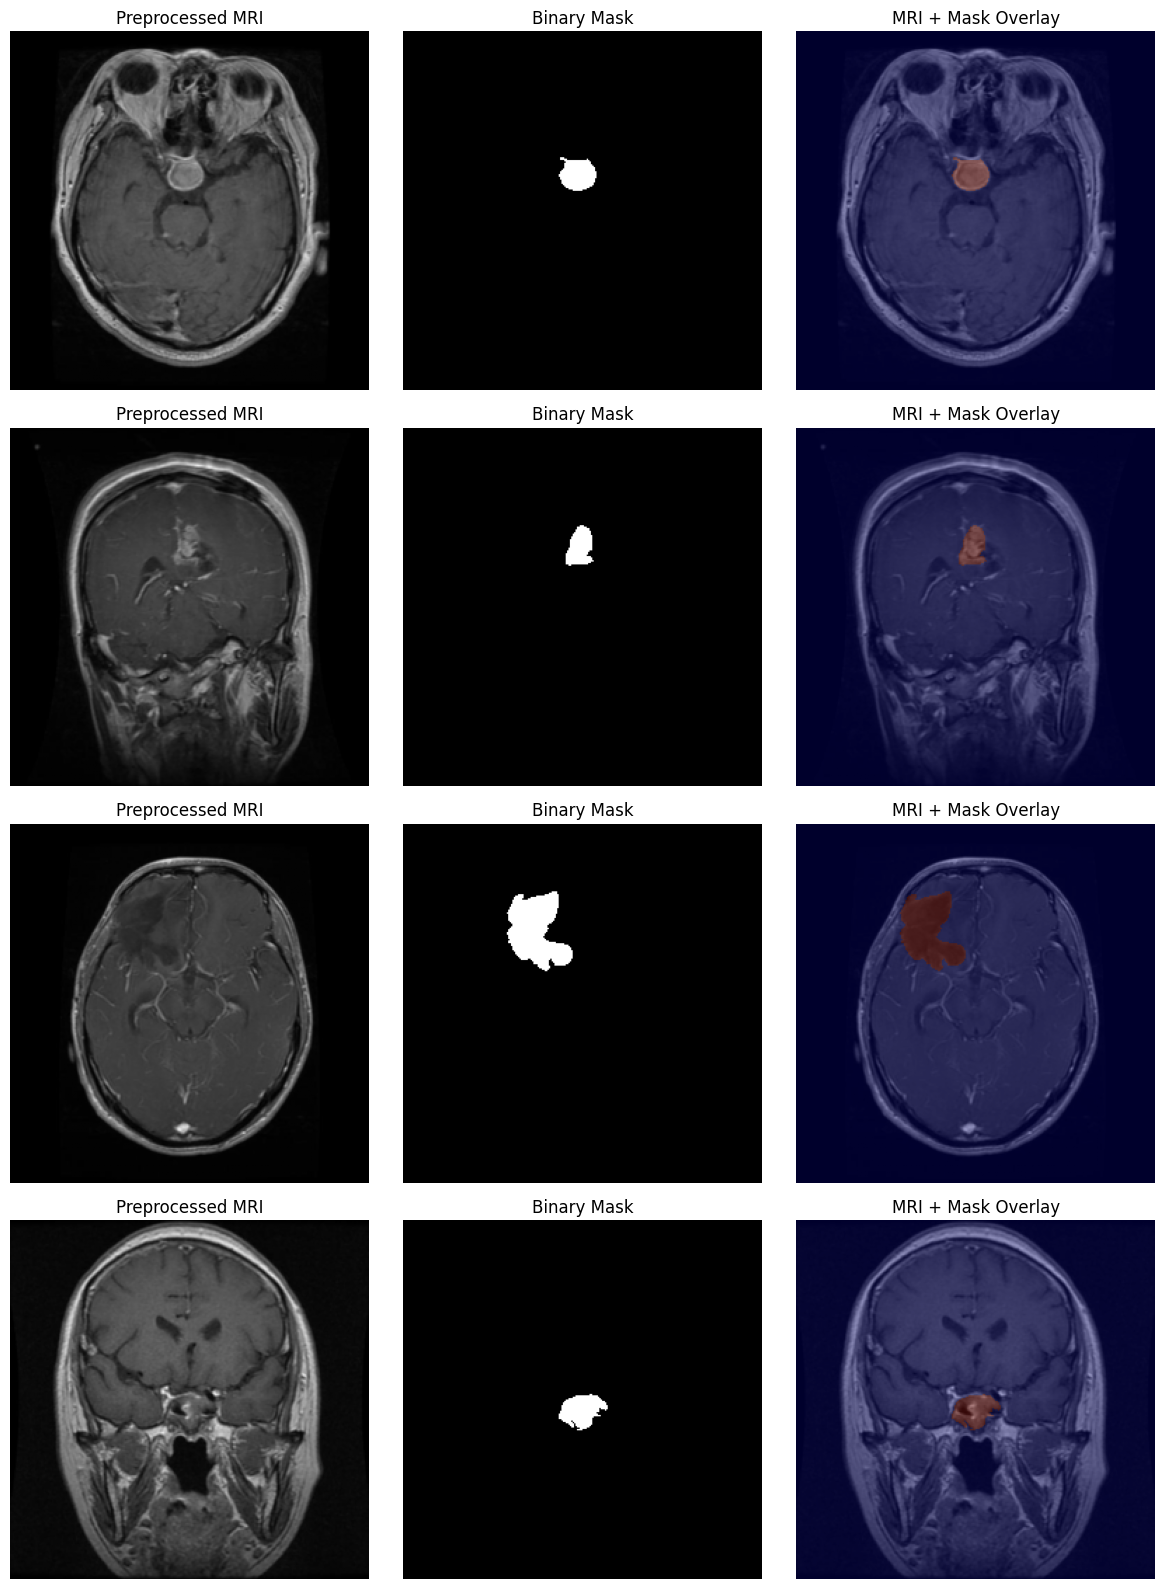

In [46]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import random

random.seed(42)

sample_files = random.sample(
    sorted(TRAIN_IMAGE_DIR.glob("*")), 4
)

fig, axes = plt.subplots(4, 3, figsize=(12, 16))

for i, image_path in enumerate(sample_files):

    mask_path = TRAIN_MASK_DIR / (image_path.stem + ".png")

    with Image.open(image_path) as img:
        processed_image = resize_with_padding(
            img.convert("RGB"), IMAGE_SIZE, is_mask=False
        )

    with Image.open(mask_path) as msk:
        processed_mask = resize_with_padding(
            msk.convert("L"), IMAGE_SIZE, is_mask=True
        )

    image_array = np.array(processed_image) / 255.0
    mask_array = np.array(processed_mask)

    axes[i, 0].imshow(image_array)
    axes[i, 0].set_title("Preprocessed MRI")

    axes[i, 1].imshow(mask_array, cmap="gray", vmin=0, vmax=255)
    axes[i, 1].set_title("Binary Mask")

    axes[i, 2].imshow(image_array)
    axes[i, 2].imshow(
        mask_array,
        cmap="jet",
        alpha=0.35,
        vmin=0,
        vmax=255
    )
    axes[i, 2].set_title("MRI + Mask Overlay")

    for j in range(3):
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

Step 31: Full Training Dataset Preprocessing

In [49]:
from PIL import Image
from pathlib import Path
from tqdm.auto import tqdm
import numpy as np

# Check output folders before processing
if any(TRAIN_OUTPUT_IMAGES.iterdir()) or any(TRAIN_OUTPUT_MASKS.iterdir()):
    raise FileExistsError(
        "Training output folders are not empty. "
        "Check existing files before proceeding."
    )

train_image_files = sorted(
    p for p in TRAIN_IMAGE_DIR.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
)

processed_count = 0
missing_masks = []
failed_files = []

for image_path in tqdm(train_image_files):

    try:
        mask_path = TRAIN_MASK_DIR / (image_path.stem + ".png")

        if not mask_path.exists():
            missing_masks.append(image_path.name)
            continue

        # Process MRI image
        with Image.open(image_path) as img:
            image = img.convert("RGB")

            processed_image = resize_with_padding(
                image,
                IMAGE_SIZE,
                is_mask=False
            )

        # Process corresponding mask
        with Image.open(mask_path) as msk:
            mask = msk.convert("L")

            processed_mask = resize_with_padding(
                mask,
                IMAGE_SIZE,
                is_mask=True
            )

        # Save preprocessed image and mask
        processed_image.save(
            TRAIN_OUTPUT_IMAGES / (image_path.stem + ".png")
        )

        processed_mask.save(
            TRAIN_OUTPUT_MASKS / (image_path.stem + ".png")
        )

        processed_count += 1

    except Exception as e:
        failed_files.append((image_path.name, str(e)))


print("\nTRAINING PREPROCESSING SUMMARY")
print("Total source images:", len(train_image_files))
print("Successfully processed:", processed_count)
print("Missing masks:", len(missing_masks))
print("Failed files:", len(failed_files))

FileExistsError: Training output folders are not empty. Check existing files before proceeding.

Step 32: Verify Preprocessed Training Dataset

In [50]:
from pathlib import Path
from PIL import Image
import numpy as np

# Step 32.1: Define paths
BASE_DIR = Path("/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET")

OUTPUT_DIR = BASE_DIR / "BRISC_preprocessed_256_v2"

TRAIN_OUTPUT_IMAGES = OUTPUT_DIR / "train" / "images"
TRAIN_OUTPUT_MASKS = OUTPUT_DIR / "train" / "masks"

TEST_OUTPUT_IMAGES = OUTPUT_DIR / "test" / "images"
TEST_OUTPUT_MASKS = OUTPUT_DIR / "test" / "masks"

# Step 32.2: Check folders
print("Folder check:")
print("Train images folder:", TRAIN_OUTPUT_IMAGES.exists())
print("Train masks folder:", TRAIN_OUTPUT_MASKS.exists())

# Step 32.3: Count files
train_images = sorted(TRAIN_OUTPUT_IMAGES.glob("*.png"))
train_masks = sorted(TRAIN_OUTPUT_MASKS.glob("*.png"))

print("\nTRAINING OUTPUT VERIFICATION")
print("Train images:", len(train_images))
print("Train masks:", len(train_masks))

# Step 32.4: Check 10 image-mask pairs
print("\nChecking 10 sample pairs:")

for image_path in train_images[:10]:

    mask_path = TRAIN_OUTPUT_MASKS / image_path.name

    if not mask_path.exists():
        print("Missing mask:", image_path.name)
        continue

    with Image.open(image_path) as img:
        image_size = img.size

    with Image.open(mask_path) as mask:
        mask_size = mask.size
        mask_values = np.unique(np.array(mask))

    print(
        image_path.name,
        "| Image:", image_size,
        "| Mask:", mask_size,
        "| Mask values:", mask_values
    )

Folder check:
Train images folder: True
Train masks folder: True

TRAINING OUTPUT VERIFICATION
Train images: 3933
Train masks: 3933

Checking 10 sample pairs:
brisc2025_train_00001_gl_ax_t1.png | Image: (256, 256) | Mask: (256, 256) | Mask values: [  0 255]
brisc2025_train_00002_gl_ax_t1.png | Image: (256, 256) | Mask: (256, 256) | Mask values: [  0 255]
brisc2025_train_00003_gl_ax_t1.png | Image: (256, 256) | Mask: (256, 256) | Mask values: [  0 255]
brisc2025_train_00004_gl_ax_t1.png | Image: (256, 256) | Mask: (256, 256) | Mask values: [  0 255]
brisc2025_train_00005_gl_ax_t1.png | Image: (256, 256) | Mask: (256, 256) | Mask values: [  0 255]
brisc2025_train_00006_gl_ax_t1.png | Image: (256, 256) | Mask: (256, 256) | Mask values: [  0 255]
brisc2025_train_00007_gl_ax_t1.png | Image: (256, 256) | Mask: (256, 256) | Mask values: [  0 255]
brisc2025_train_00008_gl_ax_t1.png | Image: (256, 256) | Mask: (256, 256) | Mask values: [  0 255]
brisc2025_train_00009_gl_ax_t1.png | Image: (256,

Step 33: BRISC Test Dataset Preprocessing

In [51]:
from pathlib import Path

BASE_DIR = Path("/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET")

BRISC_RAW = BASE_DIR / "BRISC_RAW"
BRISC_ROOT = BRISC_RAW / "brisc2025"
segmentation_dir = BRISC_ROOT / "segmentation_task"

TEST_SOURCE_IMAGES = segmentation_dir / "test" / "images"
TEST_SOURCE_MASKS = segmentation_dir / "test" / "masks"

OUTPUT_DIR = BASE_DIR / "BRISC_preprocessed_256_v2"

TEST_OUTPUT_IMAGES = OUTPUT_DIR / "test" / "images"
TEST_OUTPUT_MASKS = OUTPUT_DIR / "test" / "masks"

print("Source images folder:", TEST_SOURCE_IMAGES.exists())
print("Source masks folder:", TEST_SOURCE_MASKS.exists())
print("Output images folder:", TEST_OUTPUT_IMAGES.exists())
print("Output masks folder:", TEST_OUTPUT_MASKS.exists())

print("\nSource image count:", len(list(TEST_SOURCE_IMAGES.glob("*"))))
print("Source mask count:", len(list(TEST_SOURCE_MASKS.glob("*"))))

Source images folder: True
Source masks folder: True
Output images folder: True
Output masks folder: True

Source image count: 860
Source mask count: 860


33.1 — Test Output Folder Check

In [52]:
from pathlib import Path

print("TEST OUTPUT FOLDER CHECK")
print("-------------------------")

existing_images = list(TEST_OUTPUT_IMAGES.glob("*"))
existing_masks = list(TEST_OUTPUT_MASKS.glob("*"))

print("Existing test images:", len(existing_images))
print("Existing test masks:", len(existing_masks))

if len(existing_images) == 0 and len(existing_masks) == 0:
    print("\nReady for test preprocessing.")
else:
    print("\nSTOP: Output folders are not empty.")
    print("Existing files will not be overwritten.")

TEST OUTPUT FOLDER CHECK
-------------------------
Existing test images: 0
Existing test masks: 0

Ready for test preprocessing.


33.2 — BRISC Test Dataset Preprocessing

In [53]:
from PIL import Image
from pathlib import Path
from tqdm.notebook import tqdm

# Configuration
IMAGE_SIZE = (256, 256)
MASK_THRESHOLD = 128  # Provisional threshold

def resize_with_padding(image, target_size=(256, 256), is_mask=False):

    target_w, target_h = target_size
    original_w, original_h = image.size

    scale = min(target_w / original_w, target_h / original_h)

    new_w = round(original_w * scale)
    new_h = round(original_h * scale)

    if is_mask:
        image = image.point(
            lambda p: 255 if p >= MASK_THRESHOLD else 0
        )
        interpolation = Image.Resampling.NEAREST
        fill_value = 0
    else:
        interpolation = Image.Resampling.BILINEAR
        fill_value = 0

    resized = image.resize((new_w, new_h), interpolation)

    canvas = Image.new(
        "L" if is_mask else "RGB",
        target_size,
        fill_value
    )

    left = (target_w - new_w) // 2
    top = (target_h - new_h) // 2

    canvas.paste(resized, (left, top))

    return canvas


# Collect source files
test_image_files = sorted(TEST_SOURCE_IMAGES.glob("*"))

processed = 0
missing_masks = []
failed_files = []

# Safety check
if any(TEST_OUTPUT_IMAGES.iterdir()) or any(TEST_OUTPUT_MASKS.iterdir()):
    raise FileExistsError(
        "Test output folders are not empty. Stopping to protect existing files."
    )

# Preprocessing
for image_path in tqdm(test_image_files):

    mask_path = TEST_SOURCE_MASKS / (image_path.stem + ".png")

    try:
        if not mask_path.exists():
            missing_masks.append(image_path.name)
            continue

        with Image.open(image_path) as img:
            img = img.convert("RGB")
            processed_image = resize_with_padding(
                img, IMAGE_SIZE, is_mask=False
            )

        with Image.open(mask_path) as mask:
            mask = mask.convert("L")
            processed_mask = resize_with_padding(
                mask, IMAGE_SIZE, is_mask=True
            )

        output_image_path = TEST_OUTPUT_IMAGES / (image_path.stem + ".png")
        output_mask_path = TEST_OUTPUT_MASKS / (image_path.stem + ".png")

        processed_image.save(output_image_path)
        processed_mask.save(output_mask_path)

        processed += 1

    except Exception as e:
        failed_files.append((image_path.name, str(e)))


# Summary
print("\nTEST PREPROCESSING SUMMARY")
print("--------------------------")
print("Total source images:", len(test_image_files))
print("Successfully processed:", processed)
print("Missing masks:", len(missing_masks))
print("Failed files:", len(failed_files))

if missing_masks:
    print("Missing mask files:", missing_masks[:10])

if failed_files:
    print("Failed files:", failed_files[:10])

  0%|          | 0/860 [00:00<?, ?it/s]


TEST PREPROCESSING SUMMARY
--------------------------
Total source images: 860
Successfully processed: 860
Missing masks: 0
Failed files: 0


Step 34 — Test Dataset Output Verification

In [54]:
from PIL import Image
import numpy as np

# Step 34.1: Count output files
test_images = sorted(TEST_OUTPUT_IMAGES.glob("*.png"))
test_masks = sorted(TEST_OUTPUT_MASKS.glob("*.png"))

print("TEST OUTPUT VERIFICATION")
print("------------------------")
print("Test images:", len(test_images))
print("Test masks:", len(test_masks))

# Step 34.2: Check 10 image-mask pairs
print("\nChecking 10 sample pairs:")

for image_path in test_images[:10]:

    mask_path = TEST_OUTPUT_MASKS / image_path.name

    if not mask_path.exists():
        print("Missing mask:", image_path.name)
        continue

    with Image.open(image_path) as img:
        image_size = img.size
        image_mode = img.mode

    with Image.open(mask_path) as mask:
        mask_size = mask.size
        mask_values = np.unique(np.array(mask))

    print(
        image_path.name,
        "| Image:", image_size,
        "| Mode:", image_mode,
        "| Mask:", mask_size,
        "| Mask values:", mask_values
    )

TEST OUTPUT VERIFICATION
------------------------
Test images: 860
Test masks: 860

Checking 10 sample pairs:
brisc2025_test_00001_gl_ax_t1.png | Image: (256, 256) | Mode: RGB | Mask: (256, 256) | Mask values: [  0 255]
brisc2025_test_00002_gl_ax_t1.png | Image: (256, 256) | Mode: RGB | Mask: (256, 256) | Mask values: [  0 255]
brisc2025_test_00003_gl_ax_t1.png | Image: (256, 256) | Mode: RGB | Mask: (256, 256) | Mask values: [  0 255]
brisc2025_test_00004_gl_ax_t1.png | Image: (256, 256) | Mode: RGB | Mask: (256, 256) | Mask values: [  0 255]
brisc2025_test_00005_gl_ax_t1.png | Image: (256, 256) | Mode: RGB | Mask: (256, 256) | Mask values: [  0 255]
brisc2025_test_00006_gl_ax_t1.png | Image: (256, 256) | Mode: RGB | Mask: (256, 256) | Mask values: [  0 255]
brisc2025_test_00007_gl_ax_t1.png | Image: (256, 256) | Mode: RGB | Mask: (256, 256) | Mask values: [  0 255]
brisc2025_test_00008_gl_ax_t1.png | Image: (256, 256) | Mode: RGB | Mask: (256, 256) | Mask values: [  0 255]
brisc2025_

Step 35 — Final BRISC Dataset Summary

In [55]:
# Step 35: Final BRISC dataset summary

train_images = sorted(TRAIN_OUTPUT_IMAGES.glob("*.png"))
train_masks = sorted(TRAIN_OUTPUT_MASKS.glob("*.png"))

test_images = sorted(TEST_OUTPUT_IMAGES.glob("*.png"))
test_masks = sorted(TEST_OUTPUT_MASKS.glob("*.png"))

# Check filename matching
train_image_names = {p.stem for p in train_images}
train_mask_names = {p.stem for p in train_masks}

test_image_names = {p.stem for p in test_images}
test_mask_names = {p.stem for p in test_masks}

print("FINAL BRISC PREPROCESSING SUMMARY")
print("---------------------------------")

print("\nTRAIN DATASET")
print("Images:", len(train_images))
print("Masks:", len(train_masks))
print("Missing masks:", len(train_image_names - train_mask_names))
print("Extra masks:", len(train_mask_names - train_image_names))

print("\nTEST DATASET")
print("Images:", len(test_images))
print("Masks:", len(test_masks))
print("Missing masks:", len(test_image_names - test_mask_names))
print("Extra masks:", len(test_mask_names - test_image_names))

print("\nTOTAL")
print("Images:", len(train_images) + len(test_images))
print("Masks:", len(train_masks) + len(test_masks))

FINAL BRISC PREPROCESSING SUMMARY
---------------------------------

TRAIN DATASET
Images: 3933
Masks: 3933
Missing masks: 0
Extra masks: 0

TEST DATASET
Images: 860
Masks: 860
Missing masks: 0
Extra masks: 0

TOTAL
Images: 4793
Masks: 4793


Step 36.1 — Documentation

In [56]:
from pathlib import Path
from datetime import date

BASE_DIR = Path("/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET")

REPORT_PATH = BASE_DIR / "BRISC_preprocessing_report.md"

report = """
# BRISC Dataset Preprocessing Report

## 1. Dataset Information

Dataset: BRISC 2025 - Brain Tumor MRI Dataset

Task: Brain Tumor Segmentation

Image type: T1-weighted MRI

Preprocessed image size: 256 x 256 pixels

## 2. Dataset Split

| Split | MRI Images | Segmentation Masks |
|---|---:|---:|
| Training | 3933 | 3933 |
| Testing | 860 | 860 |
| Total | 4793 | 4793 |

## 3. Preprocessing Operations

### 3.1 Image Conversion
- MRI images were converted to RGB format.

### 3.2 Image Resizing
- Target size: 256 x 256 pixels.
- Aspect ratio was preserved.
- Padding was added to fit the target dimensions.
- Bilinear interpolation was used for MRI images.

### 3.3 Mask Processing
- Masks were converted to grayscale.
- A provisional threshold of 128 was applied:
  - Pixel values >= 128 were converted to 255.
  - Pixel values < 128 were converted to 0.
- Nearest Neighbor interpolation was used for mask resizing.
- Zero padding was applied.

### 3.4 Output Format
- Preprocessed MRI images: PNG, RGB.
- Preprocessed masks: PNG, grayscale binary.
- Image dimensions: 256 x 256.
- Mask pixel values: 0 and 255.

## 4. Preprocessing Results

### Training Dataset
- Source images: 3933
- Successfully processed: 3933
- Missing masks: 0
- Failed files: 0

### Testing Dataset
- Source images: 860
- Successfully processed: 860
- Missing masks: 0
- Failed files: 0

## 5. Output Verification

- Training image count: 3933
- Training mask count: 3933
- Testing image count: 860
- Testing mask count: 860
- Missing training masks: 0
- Extra training masks: 0
- Missing testing masks: 0
- Extra testing masks: 0

Ten training image-mask pairs and ten testing image-mask pairs
were checked for dimensions and mask pixel values.

All inspected samples had matching 256 x 256 dimensions.
Their mask values were 0 and 255.

Note: Sample verification does not constitute a complete
pixel-level validation of every output file.

## 6. Important Methodological Note

The threshold value of 128 was used provisionally because the
dataset README describes binary segmentation masks but does not
specify an exact grayscale threshold.

The threshold must be confirmed against the dataset's original
mask encoding or dataset authors' documentation before making
a final scientific claim about mask interpretation.

## 7. Output Directory

BRISC_preprocessed_256_v2/
    train/
        images/
        masks/
    test/
        images/
        masks/

## 8. Data Integrity

The original BRISC dataset was kept unchanged.
Preprocessed files were saved in a separate output directory.

The original training and testing split was preserved.

## 9. Completion Status

Training preprocessing: Completed
Testing preprocessing: Completed
Filename matching: Completed
Sample output verification: Completed

Documentation generated: """ + str(date.today()) + """

"""

REPORT_PATH.write_text(report, encoding="utf-8")

print("Documentation created successfully!")
print("Saved location:", REPORT_PATH)
print("File exists:", REPORT_PATH.exists())

Documentation created successfully!
Saved location: /content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/BRISC_preprocessing_report.md
File exists: True
